# load libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import scipy.stats as st

import math
import os
import datetime
from sklearn.linear_model import LinearRegression

from sklearn.cluster import KMeans
sns.set_context('paper')
import gseapy
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler
import warnings
from itertools import combinations
warnings.filterwarnings("ignore")
import sys
sys.path.append('/lustre1/home/martinmikl/sshanas/bin')
from div import *

sns.set_context('paper')
plt.rcParams.update({
    'font.size': 10 * 0.6,
    'axes.titlesize': 10 * 0.6,
    'axes.labelsize': 10 * 0.6,
    'xtick.labelsize': 10 * 0.6,
    'ytick.labelsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'figure.titlesize': 12 * 0.6,
    'legend.title_fontsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans']
})

def nnow():
    print(datetime.datetime.now().strftime('%Y-%m-%d  %H:%M:%S'))
nnow()


s_colors =  ["#ff6f61", "#1f77b4", "#2ca02c"] 

2026-10-14  17:32:41


# load data

In [ ]:
nnow()
input_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_upstream_git/'
tpm = pd.read_csv(input_path  + 'gene_tpm.csv.gz', index_col=0)
tpm = np.log2(tpm + 1)
tpm_untn = pd.read_csv(input_path  + 'gene_tpm.csv.gz', index_col=0)
div = pd.read_csv(input_path  + 'div1.csv.gz', index_col=0)
nis = pd.read_csv(input_path  + 'nisoforms_expressed.csv.gz', index_col=0)
metadata = pd.read_csv(input_path  + 'metadata.csv.gz', index_col=0)
gene_info = pd.read_csv(input_path  + 'gene_annotation.csv.gz', index_col=0)
pearson_correlations_tpm_div_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_pre_downstream_git/fig1_idiv_tpm_pearosn/div_tpm/SMTS.pearson.csv'
pth = os.getcwd() + '/'
source_data_path = pth + 'source_data/'
supplementary_data_path = pth + 'supplementary_data/'

if not os.path.isdir(pth + 'figs_intro/'):
    os.mkdir(pth + 'figs_intro/')
if not os.path.isdir(pth + 'tables_intro/'):
    os.mkdir(pth + 'tables_intro/')

2026-10-13  13:58:21


In [2]:
input_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_upstream_git/4.outputs/'
metadata = pd.read_csv(input_path  + 'metadata.csv.gz', index_col=0)


In [4]:
metadata.donor.nunique()

267

In [5]:
metadata.SMTSD.nunique()

47

# functions to make dataframes

In [5]:
nnow()
def get_isoforms_from_gene(gene):
    ''' This function gets a gene name or gene id and returns the isoforms of this gene with their expression values in the readtpm_t.csv.gz file.
    Args:
        gene: A string which is either a gene name or a gene id.
    Returns:
        A dataframe which contains the isoforms of the gene with their expression values in the readtpm_t.csv.gz file.
    '''
    if gene[:4] != 'ENSG':
        gid = gene_info.loc[gene_info['gene_name'] == gene].index[0]
    else:
        gid = gene
    rows = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.1/readtpm_t.csv.gz', usecols=['accession_number'])
    rows_to_skip = rows[~rows['accession_number'].str.contains(gid)].index + 1
    isof_df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.1/readtpm_t.csv.gz', skiprows=rows_to_skip, index_col='accession_number')
    return isof_df

def get_gene_metrics(gene):
    ''' This function gets a gene name or gene id and returns a dataframe which contains the metrics of this gene in the readtpm_t.csv.gz, div1.csv.gz and nisoforms_expressed.csv.gz files.
    Args:
        gene: A string which is either a gene name or a gene id.
    Returns:
        A dataframe which contains the metrics of the gene in the readtpm_t.csv.gz, div1.csv.gz and nisoforms_expressed.csv.gz files. '''
    if gene[:4] != 'ENSG':
        gene = gene_info.loc[gene_info['gene_name'] == gene].index[0]

    gene_metrics = div.loc[[gene]][div.loc[[gene]] > 0].T
    gene_metrics = gene_metrics.join(metadata[['SMTS', 'SMTSD', 'system']]).dropna().rename(columns={gene: 'I-DIV'})
    gene_metrics = gene_metrics.join(nis.loc[[gene]].T).rename(columns={gene: 'NIS'})
    gene_metrics = gene_metrics.join(tpm.loc[[gene]].T).rename(columns={gene:'TPM'})
    return gene_metrics



def scale_with_MinMax(smpl, minval = 10**-2):
    scaler = MinMaxScaler(feature_range=(minval, 1))
    plot_data = isoforms_df[[smpl]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)

    plot_data = plot_data.assign(minmax = scaler.fit_transform(plot_data[[smpl]]))
    plot_data = plot_data.assign(percentiles = plot_data['minmax'].rank(pct=True, method='first') * 100).sort_values('minmax', ascending=True)
    return plot_data

def isoform_expression_barplots(smpl:str, isoforms_df, gn, n_nis, savefig=False, info='', o = ''):
    plot_data = isoforms_df[[smpl]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)
    plot_data = plot_data.assign(isof_idx = range(len(plot_data)), 
                                log2 = plot_data[plot_data.columns[0]].apply(lambda x: math.log2(x+1)))
    color_palette = {t:sns.color_palette('plasma_r', len(plot_data)).as_hex()[i] for i,t in enumerate(plot_data.isof_idx) }
    
    fig, ax = plt.subplots(figsize=(0.75,0.75))
    plot_data.plot.bar(x="isof_idx", y="log2", rot=0, ax = ax, color = plot_data.reset_index().index.map(color_palette), legend=False, width=0.9)
    ax.tick_params(length=2.5) ## other options are right and top
    ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
    ax.set_xticks([])
    gid = gene_info.loc[gene_info['gene_name'] == gn].index[0]
    # ax.set(title=f'I-DIV={div.loc[gid, smpl]:.2f}', ylabel='I-TPM [log2]', xlabel='isoforms')
    ax.set(ylabel='Isoform level\nTPM [log2]', xlabel='isoforms')
    ax.set_title(f'I-DIV={div.loc[gid, smpl]:.2f}', loc='left', y = 0.9)
    
    ax.set_xlabel(ax.get_xlabel(),labelpad=0.5) 
    ax.set_ylabel(ax.get_ylabel(),labelpad=0) 
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)     
    ax.patch.set_facecolor('None')
    # ax.set_yscale('log')
    
    if len(o) >= 1:
        o += '/'

    if not os.path.isdir(pth + f'figs_intro/{o}'):
        os.mkdir(pth + f'figs_intro/{o}')
    
    if savefig:
        if info:
            fig.savefig(pth + f'figs_intro/{o}' + f'{gn}.{n_nis}_NIS.{info}.bar.png', format='png', dpi=300, bbox_inches='tight')
        else:
            fig.savefig(pth + f'figs_intro/{o}' + f'{gn}.{n_nis}_NIS.bar.png', format='png', dpi=300, bbox_inches='tight')

    fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
    plot_data[[plot_data.columns[0], 'isof_idx']].set_index('isof_idx').T.plot(kind='barh', stacked=True, legend=False, color=color_palette, width=0.1, ax=ax) # , edgecolor='whitesmoke'
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)     
    ax.patch.set_facecolor('None')
    ax.set_xticks([])
    ax.set_yticks([])
    # ax.text(x=0.45, y=0.05, s='I-TPM RA', transform=ax.transAxes, ha = 'center')
    # ax.set_xlabel('I-TPM RA',y=50) 
    ax.set_title('Isoform level TPM\nRelative abundance',y=-0.03) 
    if savefig:
        if info:
            fig.savefig(pth + f'figs_intro/{o}' + f'{gn}.{n_nis}_NIS.{metadata.loc[smpl, "SMTSD"]}.{info}.bar_stack.png', format='png', dpi=300, bbox_inches='tight')
        else:
            fig.savefig(pth + f'figs_intro/{o}' + f'{gn}.{n_nis}_NIS.{metadata.loc[smpl, "SMTSD"]}.bar_stack.png', format='png', dpi=300, bbox_inches='tight')


def isoform_expression_lineplot(spl_min, spl_max, gn ,n_nis, savefig=False, info='',o=''):
    plot_data_min = scale_with_MinMax(smpl = spl_min)
    plot_data_max = scale_with_MinMax(smpl = spl_max)
    fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
    sns.lineplot(data=plot_data_max, x='percentiles', y='minmax', color=s_colors[0], marker='h', markersize=3, linewidth = 0.25, alpha = 0.7, markeredgewidth=0, ax =ax)
    sns.lineplot(data=plot_data_min, x='percentiles', y='minmax', color=s_colors[1], marker='h', markersize=3, linewidth = 0.25, alpha = 0.7, markeredgewidth=0, ax =ax)
    ax.set_yscale('log')
    ax.set(ylabel='Isoform level TPM\nnorm.', xlabel='Isoform level TPM\npercentile')
    ax.tick_params(length=2.5) ## other options are right and top
    ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
    ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
    ax.set_xlabel(ax.get_xlabel(),labelpad=0)
    ax.set_ylabel(ax.get_ylabel(),labelpad=0)
    sns.despine()
    
    if len(o) >= 1:
        o += '/'
        
    if savefig:
        if info:
            fig.savefig(pth + f'figs_intro/{o}' + f'{gn}.{n_nis}_NIS.{info}.lineplots.png', format='png', dpi=300, bbox_inches='tight')
        else:
            fig.savefig(pth + f'figs_intro/{o}' + f'{gn}.{n_nis}_NIS.lineplots.png', format='png', dpi=300, bbox_inches='tight')

brain_regions_abb = {
    'Brain - Cortex': 'CTX',
    'Brain - Cerebellum': 'CBL',
    'Brain - Hippocampus': 'HIP',
    'Brain - Anterior cingulate cortex (BA24)': 'ACC',
    'Brain - Caudate (basal ganglia)': 'CAU',
    'Brain - Nucleus accumbens (basal ganglia)': 'NAC',
    'Brain - Putamen (basal ganglia)': 'PUT',
    'Brain - Frontal Cortex (BA9)': 'FCX',
    'Brain - Cerebellar Hemisphere': 'CBH',
    'Brain - Hypothalamus': 'HYP',
    'Brain - Substantia nigra': 'SNI',
    'Brain - Spinal cord (cervical c-1)': 'SPC',
    'Brain - Amygdala': 'AMY',
}

abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}

2026-10-13  13:58:06


NameError: name 'metadata' is not defined

# functions to make plots

In [4]:
nnow()
def format_small_number(v):
    if 'e' in str(v):
        val, x, powerof = str(v).replace("e", "x10^").split(' ')
        formatted = ''.join([f"{float(val):.2f}", x, powerof])
    else:
        formatted = f"{v:.2f}"
    return formatted


def annotpval(pv):
    if float(f'{pv:.2e}') == 0.00e+00:
        return 'p<10^-323'
    else:
        return f'p={pv:.2e}'.replace("e", "x10^")

2026-10-13  10:58:18


# isoform DIV description examples


## BRCA1

In [8]:
gn = 'BRCA1'
isoforms_df = get_isoforms_from_gene(gene=gn)
gene_metrics = get_gene_metrics(gene=gn)

In [ ]:
isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
isoforms_df.to_csv(source_data_path + f'1c.csv.gz', compression='gzip', index=True)
gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)
gene_metrics.to_csv(source_data_path + f'1c_topleft.csv.gz', compression='gzip', index=True)


In [98]:
# gn = 'BRCA1'
# isoforms_df = pd.read_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index_col='accession_number')
# gene_metrics = pd.read_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index_col='Unnamed: 0')

In [75]:
if not os.path.isdir(pth + 'figs_intro/' + gn): 
    os.mkdir(pth + 'figs_intro/' + gn)


BRCA1 gene
number of samples: 4813
number of isoforms from samples chosen for the example: 6

(a) Scatterplot: of BRCA1 gene. Every datapoint is a sample (n=4813). Orange and blue hexagon datapoints represent examples of two samples of the gene 
(Orange=Brain - Cerebellum ; Blue=Liver) that share the same number of isoforms (6), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=6
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=6
The colors between the bar and the stacked are matched to the same isoforms.
(b) Bar plot + stacked bar plot represent the isoform diversity of the cerebellum sample
(d) Bar plot + stacked bar plot represent the isoform diversity of the liver sample
(c) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Or

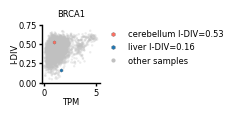

In [77]:

fig, ax = plt.subplots(figsize=(0.75, 0.75))
nnis = 6
maxdiv = gene_metrics.loc[(gene_metrics.NIS == nnis) , 'I-DIV'].idxmax()
mindiv = gene_metrics.loc[(gene_metrics.NIS == nnis) , 'I-DIV'].idxmin()
sns.scatterplot(data=gene_metrics, x='TPM', y='I-DIV', edgecolor='none', c='silver', alpha = 0.3, s = 3,
                ax=ax)
for i,s in enumerate([ maxdiv,  mindiv]):    
    sns.scatterplot(data=gene_metrics.loc[[s]], x='TPM', y='I-DIV', c=s_colors[i], edgecolor='dimgrey',
                    marker='h', alpha=1, s=6, ax=ax, zorder=2)
legend_handles = [
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label='cerebellum I-DIV=' + f'{gene_metrics.loc[maxdiv, 'I-DIV']:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label='liver I-DIV=' + f'{gene_metrics.loc[mindiv, 'I-DIV']:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor='silver',
           markeredgecolor='none', markersize=3, label='other samples')
]

ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
ax.set_yticks([0,0.25,0.5,0.75])
ax.set(title='BRCA1', ylabel='I-DIV', xlabel='TPM')

ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)

sns.despine()
fig.savefig(pth + f'figs_intro/{gn}/' + f'{gn}.scatter.png', format='png', dpi=300, bbox_inches='tight')

pearsons_res = {}
pearsons_res['DIV_TPM_' + 'r'], pearsons_res['DIV_TPM_' + 'p'] = st.pearsonr(gene_metrics['I-DIV'], gene_metrics['TPM'])
pearsons_res['DIV_NIS_' + 'r'], pearsons_res['DIV_NIS_' + 'p'] = st.pearsonr(gene_metrics['I-DIV'], gene_metrics['NIS'])


s = f'''
{gn} gene
number of samples: {len(gene_metrics)}
number of isoforms from samples chosen for the example: {nnis}

(a) Scatterplot: of BRCA1 gene. Every datapoint is a sample (n={len(gene_metrics)}). Orange and blue hexagon datapoints represent examples of two samples of the gene 
(Orange={gene_metrics.loc[maxdiv, 'SMTSD']} ; Blue={gene_metrics.loc[mindiv, 'SMTSD']}) that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
The colors between the bar and the stacked are matched to the same isoforms.
(b) Bar plot + stacked bar plot represent the isoform diversity of the cerebellum sample
(d) Bar plot + stacked bar plot represent the isoform diversity of the liver sample
(c) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.

*** pearsons correlations ***
I-DIV VS TPM
r = {pearsons_res['DIV_TPM_' + 'r']:.2f}, {annotpval(pearsons_res['DIV_TPM_' + 'p'])}
I-DIV VS NIS
r = {pearsons_res['DIV_NIS_' + 'r']:.2f}, {annotpval(pearsons_res['DIV_NIS_' + 'p'])}

'''


with open(pth + f'figs_intro/{gn}/' + f'{gn}.about.txt', 'w') as f: 
    f.write(s)
    f.close()

print(s)

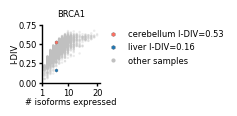

In [78]:
fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.scatterplot(data=gene_metrics, x='NIS', y='I-DIV', edgecolor='none', c='silver', alpha = 0.3, s = 3,
                ax=ax)

for i,s in enumerate([ maxdiv,  mindiv]):    
    sns.scatterplot(data=gene_metrics.loc[[s]], x='NIS', y='I-DIV', c=s_colors[i], edgecolor='dimgrey',
                    marker='h', alpha=1, s=6, ax=ax, zorder=2)
legend_handles = [
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label='cerebellum I-DIV=' + f'{gene_metrics.loc[maxdiv, 'I-DIV']:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label='liver I-DIV=' + f'{gene_metrics.loc[mindiv, 'I-DIV']:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor='silver',
           markeredgecolor='none', markersize=3, label='other samples')
]
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
ax.set_yticks([0,0.25,0.5,0.75])
ax.set_xticks([1,10,20])
ax.set(title='BRCA1', ylabel='I-DIV', xlabel='# isoforms expressed')

ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()
fig.savefig(pth + f'figs_intro/{gn}/' + f'{gn}.IDIV_NIS.scatter.png', format='png', dpi=300, bbox_inches='tight')

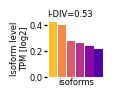

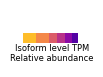

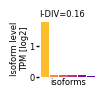

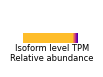

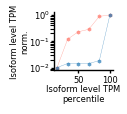

In [109]:
isoform_expression_barplots(smpl = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax(), isoforms_df = isoforms_df, gn = gn, n_nis = nnis, savefig=True, info='maxDIV',o=gn + '/')
isoform_expression_barplots(smpl = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin(), isoforms_df = isoforms_df, gn = gn, n_nis = nnis, savefig=True, info='minDIV',o=gn + '/')
isoform_expression_lineplot(spl_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin(), 
                            spl_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax(), gn = gn, n_nis = nnis, savefig=True,o=gn + '/')

## NDRG2  
**scatterplot** represents the isoform diversity (y axis) to number of expressed isoforms (x axis), every datapoint is a sample.  
shown here samples of gene expression TPM > 100 (n=3054)  
grey datapoints represent samples outsize the nervous system (n=1438)  
pink datapoints represent samples from the neuvous system (n=1616)   

3 samples with the same number of isoforms are shown for the example in hexagones:   
green hexagonal datapoint represents sample from Nerve Tibial, shows the highest isoform diversity within the examples
orange hexagonal datapoint represents sample from Hippocampus  
blue hexagonal datapoint represents sample from Cerebellar Hemisphere  , shows the lowest isoform diversity within the examples

lineplot represents the isoform expression in log scale of the different samples, ordered from highest expressed to lowest expressed (x axis), and the isoform expression in log scale (y axis)


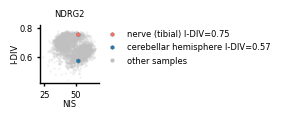

In [ ]:
gn = gene_info.loc['ENSG00000165795', 'gene_name'] # NDRG2
gene_metrics = get_gene_metrics('ENSG00000165795')

if not os.path.isdir(pth + 'figs_intro/' + gn): 
    os.mkdir(pth + 'figs_intro/' + gn)

isoforms_df = get_isoforms_from_gene(gene='ENSG00000165795')
isoforms_df.to_csv(source_data_path + f'1d_bottom.csv.gz', compression='gzip', index=True)
gene_metrics.to_csv(source_data_path + f'1d_top.csv.gz', compression='gzip', index=True)
    
samples_52_isoforms_l = ['GTEX-QXCU-0126-SM-2TC5Q', 'GTEX-16Z82-0011-R11a-SM-79OKJ'] # 'GTEX-S7SE-0011-R1A-SM-2XCDE',
samples_52_isoforms_cpalette= {s: s_colors[i] for i, s in enumerate(samples_52_isoforms_l)}

fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.despine()

sns.scatterplot(data = gene_metrics[(gene_metrics['TPM'] > 5.5) ], x = 'NIS', y='I-DIV', edgecolor='None', c='silver', alpha=0.2, s=3)
sns.scatterplot(data = gene_metrics[(gene_metrics['NIS'] == 52) & (gene_metrics.index.isin(samples_52_isoforms_l))].reset_index(), x = 'NIS', y='I-DIV', edgecolor='dimgrey', hue = 'index', 
                palette=samples_52_isoforms_cpalette, marker='h', alpha=1, s=10)
ax.set(ylabel='I-DIV', xlabel='NIS', title=gn)
ax.set_ylim(ax.set_ylim()[0], 0.82)
ax.set_title(label=gn)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_xlabel(ax.get_xlabel(),labelpad=0) 
ax.set_ylabel(ax.get_ylabel(),labelpad=0) 

legend_handles = [

    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'nerve (tibial) I-DIV={gene_metrics.loc['GTEX-QXCU-0126-SM-2TC5Q','I-DIV']:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'cerebellar hemisphere I-DIV={gene_metrics.loc['GTEX-16Z82-0011-R11a-SM-79OKJ','I-DIV']:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor='silver',
           markeredgecolor='none', markersize=3, label='other samples'),
]

ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))

fig.savefig(pth + f'figs_intro/{gn}/' + f'{gn}.scatter.52_NIS.n_{len(gene_metrics[(gene_metrics['TPM'] > 5.5)])}.png', format='png', dpi=300, bbox_inches='tight')


pearsons_res_entire = {}
pearsons_res_entire['DIV_TPM_' + 'r'], pearsons_res_entire['DIV_TPM_' + 'p'] = st.pearsonr(gene_metrics['I-DIV'], gene_metrics['TPM'])
pearsons_res_entire['DIV_NIS_' + 'r'], pearsons_res_entire['DIV_NIS_' + 'p'] = st.pearsonr(gene_metrics['I-DIV'], gene_metrics['NIS'])
pearsons_res_filtered = {}
pearsons_res_filtered['DIV_TPM_' + 'r'], pearsons_res_filtered['DIV_TPM_' + 'p'] = st.pearsonr(gene_metrics.loc[gene_metrics['TPM'] > 5.5,'I-DIV'], gene_metrics.loc[gene_metrics['TPM'] > 5.5,'TPM'])
pearsons_res_filtered['DIV_NIS_' + 'r'], pearsons_res_filtered['DIV_NIS_' + 'p'] = st.pearsonr(gene_metrics.loc[gene_metrics['TPM'] > 5.5,'I-DIV'], gene_metrics.loc[gene_metrics['TPM'] > 5.5,'NIS'])

s = f'''3. {gn} gene 
(a) scatterplot represents the isoform diversity (y axis) to number of expressed isoforms (x axis), every datapoint is a sample. 
shown here samples of gene expression log2(TPM+1) > 5.5 (n= {len(gene_metrics[(gene_metrics['TPM'] > 5.5)])})  
2 samples with the same number of isoforms (52) are shown for the example in hexagones. 
sample with higher diversity (I-DIV={gene_metrics.loc['GTEX-QXCU-0126-SM-2TC5Q','I-DIV']:.2f}) from SMTSD {gene_metrics.loc['GTEX-QXCU-0126-SM-2TC5Q','SMTSD']}
sample with lower diversity (I-DIV={gene_metrics.loc['GTEX-16Z82-0011-R11a-SM-79OKJ','I-DIV']:.2f}) from SMTSD {gene_metrics.loc['GTEX-16Z82-0011-R11a-SM-79OKJ','SMTSD']}
(b) lineplot shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform.

number of samples in the scatterplot: {len(gene_metrics[(gene_metrics['TPM'] > 5.5)])}
numbef of samples in the entire gene_metrics dataset for {gn}: {len(gene_metrics)}

*** pearsons correlations ***
*** across all the samples of NDRG2
I-DIV VS TPM
r = {pearsons_res_entire['DIV_TPM_' + 'r']:.2f}, {annotpval(pearsons_res_entire['DIV_TPM_' + 'p'])}
I-DIV VS NIS
r = {pearsons_res_entire['DIV_NIS_' + 'r']:.2f}, {annotpval(pearsons_res_entire['DIV_NIS_' + 'p'])}


*** across only datapoints shown in the figures (TPM > 5.5)
I-DIV VS TPM
r = {pearsons_res_filtered['DIV_TPM_' + 'r']:.2f}, {annotpval(pearsons_res_filtered['DIV_TPM_' + 'p'])}
I-DIV VS NIS
r = {pearsons_res_filtered['DIV_NIS_' + 'r']:.2f}, {annotpval(pearsons_res_filtered['DIV_NIS_' + 'p'])}
'''

with open(pth + f'figs_intro/{gn}/' + f'{gn}.about.txt', 'w') as f: 
    f.write(s)
    f.close()


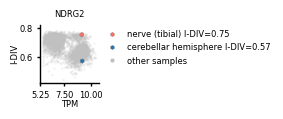

In [93]:
samples_52_isoforms_l = ['GTEX-QXCU-0126-SM-2TC5Q', 'GTEX-16Z82-0011-R11a-SM-79OKJ'] # 'GTEX-S7SE-0011-R1A-SM-2XCDE',
samples_52_isoforms_cpalette= {s: s_colors[i] for i, s in enumerate(samples_52_isoforms_l)}

fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.scatterplot(data = gene_metrics[(gene_metrics['TPM'] > 5.5) ], x = 'TPM', y='I-DIV', edgecolor='None', c='silver', alpha=0.2, s=3)

sns.scatterplot(data = gene_metrics[(gene_metrics['NIS'] == 52) & (gene_metrics.index.isin(samples_52_isoforms_l))].reset_index(), x = 'TPM', y='I-DIV', edgecolor='dimgrey', hue = 'index', 
                palette=samples_52_isoforms_cpalette, marker='h', alpha=1, s=10)
ax.set(ylabel='I-DIV', xlabel='TPM', title=gene_info.loc['ENSG00000165795', 'gene_name'])
ax.set_ylim(ax.set_ylim()[0], 0.82)
ax.set_title(label=gn)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_xlabel(ax.get_xlabel(),labelpad=0) 
ax.set_ylabel(ax.get_ylabel(),labelpad=0) 
ax.set_xticks([5.25,7.5,10])
legend_handles = [

    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'nerve (tibial) I-DIV={gene_metrics.loc['GTEX-QXCU-0126-SM-2TC5Q','I-DIV']:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'cerebellar hemisphere I-DIV={gene_metrics.loc['GTEX-16Z82-0011-R11a-SM-79OKJ','I-DIV']:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor='silver',
           markeredgecolor='none', markersize=3, label='other samples'),
]

ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
sns.despine()
fig.savefig(pth + f'figs_intro/{gn}/' + f'{gn}.scatter.52_NIS.IDIV_TPM.png', format='png', dpi=300, bbox_inches='tight')

In [17]:
pth = '/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/downstream_results/'

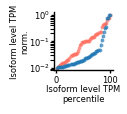

In [97]:
samples_52_isoforms_l = ['GTEX-QXCU-0126-SM-2TC5Q', 'GTEX-16Z82-0011-R11a-SM-79OKJ'] # 'GTEX-S7SE-0011-R1A-SM-2XCDE',
samples_52_isoforms_cpalette= {s: s_colors[i] for i, s in enumerate(samples_52_isoforms_l)}

fig, ax = plt.subplots(figsize=(0.75,0.75))
for c in samples_52_isoforms_cpalette.keys():
    plot_data = scale_with_MinMax(smpl = c)
    # plot_data = samples_52_isoforms_selected[[c]]
    # plot_data = plot_data[plot_data[c] > 0]
    # plot_data[c + '_rnk'] = plot_data[c].rank(pct=True) * 100
    
    # sns.lineplot(data = plot_data.sort_values('percentiles'), x = 'percentiles', y = 'minmax', linewidth = 1, alpha = 0.7, c = samples_52_isoforms_cpalette[c])
    sns.lineplot(data=plot_data.sort_values('percentiles'), x='percentiles', y='minmax', color=samples_52_isoforms_cpalette[c], marker='h', markersize=3, linewidth = 0.25, alpha = 0.7, markeredgewidth=0,
             ax =ax)
ax.set(ylabel='Isoform level TPM\nnorm.', xlabel='Isoform level TPM\npercentile')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yscale('log')
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xlabel(ax.get_xlabel(),labelpad=0) 
ax.set_ylabel(ax.get_ylabel(),labelpad=0) 
sns.despine()
fig.savefig(pth + f'figs_intro/{gn}' + f'{gn}.lineplot.png', format='png', dpi=300, bbox_inches='tight')


number of samples in the scatterplot: 4812

Scatterplot: of NDRG2 gene. Every datapoint is a sample (n=4812), colored by number of isoforms.



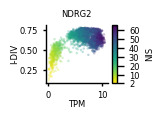

In [94]:
# fig, ax = plt.subplots(figsize=(2.5, 1.75))
fig, ax = plt.subplots(figsize=(1, 0.75))
sns.scatterplot(data=gene_metrics, x='TPM', y='I-DIV', edgecolor='none', hue='NIS', palette='viridis_r',alpha = 0.3, s = 3, legend=False, 
                ax=ax)
# ax.set_xscale('log')
ax.set(title='NDRG2', xlabel='TPM', ylabel='I-DIV')
sns.despine()

norm = plt.Normalize(gene_metrics['NIS'].min(), gene_metrics['NIS'].max())
sm = plt.cm.ScalarMappable(cmap="viridis_r", norm=norm)
sm.set_array([])
cbar = ax.figure.colorbar(sm, ax = ax, aspect= 10, ticks=range(gene_metrics['NIS'].min(), gene_metrics['NIS'].max(), 4), label='NIS')
# cbar.set_ticks([2] + [x for x in range(10,70,10)] + [66])
cbar.set_ticks([2] + [x for x in range(10,70,10)])
ax.tick_params(length=2.5) ## other options are right and top
ax.set_xlabel(ax.get_xlabel(),labelpad=0) 
ax.set_ylabel(ax.get_ylabel(),labelpad=0) 

fig.savefig(pth + f'figs_intro/{gn}' + f'{gn}.DIV_TPM.hue_NIS.n_{len(gene_metrics)}.png', format='png', dpi=300, bbox_inches='tight')
print(f'number of samples in the scatterplot: {len(gene_metrics)}')

print(f'''
Scatterplot: of {gn} gene. Every datapoint is a sample (n={len(gene_metrics)}), colored by number of isoforms.
''')

# comparison of mean isoform diversity with mean nubmer of isoforms and mean TPM per gene across samples

`DIV_nexons.scatterplot.png`: Scatterplot which compares between number of exons according to GENCODE v26 annotation (x axis) and mean isoform diversity (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}). 

`DIV_length.scatterplot.png`: Scatterplot which compares between gene length in basepairs according to from GENCODE v26 annotation (x axis) and mean isoform diversity (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}). 

`DIV_NIS.scatterplot.png`: Scatterplot which compares between mean number of expressed isoforms (x axis) and mean isoform diversity (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).  

`DIV_TPM.scatterplot.png`: Scatterplot which compares between mean gene expression in TPM (x axis) and mean isoform diversity (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).  

`DIV_npt_isoforms.scatterplot.png`: Scatterplot which compares between potential number of isoforms (x axis) and mean isoform diversity (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).  

`TPM_nexons.scatterplot.png`: Scatterplot which compares between number of exons according to GENCODE v26 annotation (x axis) and mean gene expression in log2(TPM + 1) (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).

`TPM_length.scatterplot.png`: Scatterplot which compares between gene length in basepairs according to from GENCODE v26 annotation (x axis) and mean gene expression in log2(TPM + 1) (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).  

`TPM_NIS.scatterplot.png`: Scatterplot which compares between mean number of expressed isoforms (x axis) and mean gene expression in log2(TPM + 1) (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).  

`TPM_npt_isoforms.scatterplot.png`: Scatterplot which compares between potential number of isoforms (x axis) and mean gene expression in log2(TPM + 1) (y axis) across all samples. every datapoint is a gene with at least 3 exons according to GENCODE v26, at least 3 isoforms expressed and isoform diversity above 0 (n={len(df_to_gene_features_df)}).  



In [ ]:
mean_df = gene_info[['nexons', 'length', 'npt_isoforms']].assign(**{'TPM': tpm.mean(axis='columns'), 'I-DIV': div.mean(axis='columns'), 'NIS': nis.mean(axis='columns')})
mean_df = mean_df[(mean_df.nexons > 2) & (mean_df.NIS > 2) & (mean_df['I-DIV'] > 0)]
print(f'number of genes in the scatterplot: {len(mean_df)}')
mean_df.to_csv(pth + 'tables_intro/' + 'gene_features.csv.gz', compression='gzip', index=True)
# mean_df.to_csv(tables_main_path + 'Fig1_main.gene_features.csv.gz', compression='gzip', index=True)
mean_df.to_csv(source_data_path + f'1b.csv.gz', compression='gzip', index=True)

number of genes in the scatterplot: 11981


In [ ]:
# mean_df = pd.read_csv(pth + 'tables_intro/' + 'gene_features.csv.gz', index_col='accession_number')

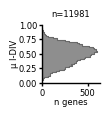

In [48]:
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.histplot(data = mean_df, y = 'I-DIV',color = 'dimgrey', element='step')
ax.set(xlabel='n genes', ylabel='µ I-DIV', title=f'n={len(mean_df.index)}')
ax.set_yticks([0,0.25,0.5,0.75,1])
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()
fig.savefig('figs_intro/' + 'meanisof_axiscolumns.png', format='png', dpi=300, bbox_inches='tight')


s = f'''
Distribution of mean isoform diversity values across GTEx samples; n = {len(mean_df.index)}.
Median: {mean_df['I-DIV'].median():.2f}
minimum val: {mean_df['I-DIV'].min():.2f}
maximum val: {mean_df['I-DIV'].max():.2f}
'''

with open(pth + 'figs_intro/' + f'meanisof_axiscolumns.about.txt', 'w') as f: 
    f.write(s)
    f.close()



In [47]:
mean_df['I-DIV'].median().round(2)

0.5

In [61]:
reg = LinearRegression().fit(mean_df[['I-DIV']], mean_df[['NIS']])
reg.score(mean_df[['I-DIV']], mean_df[['NIS']])

0.18222636954597748

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


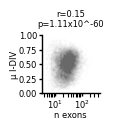

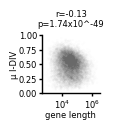

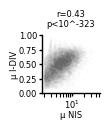

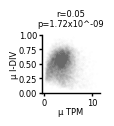

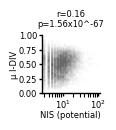

In [ ]:

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'nexons' ; Y = 'I-DIV'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ I-DIV', xlabel='n exons')
ax.legend().remove()
sns.despine()
ax.set_xscale('log')
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.set_yticks([0,0.25,0.5,0.75,1])
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'length' ; Y = 'I-DIV'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ I-DIV', xlabel='gene length')
ax.legend().remove()
sns.despine()
ax.set_xscale('log')
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.set_yticks([0,0.25,0.5,0.75,1])
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'NIS' ; Y = 'I-DIV'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ I-DIV', xlabel='µ NIS')
ax.legend().remove()
sns.despine()
ax.set_xscale('log')
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.set_yticks([0,0.25,0.5,0.75,1])
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'TPM' ; Y = 'I-DIV'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ I-DIV', xlabel='µ TPM')
ax.legend().remove()
sns.despine()
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.set_yticks([0,0.25,0.5,0.75,1])
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'npt_isoforms' ; Y = 'I-DIV'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ I-DIV', xlabel='NIS (potential)')
ax.legend().remove()
sns.despine()
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.set_yticks([0,0.25,0.5,0.75,1])
ax.set_xscale('log')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


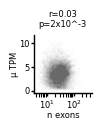

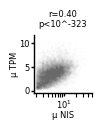

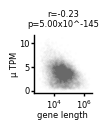

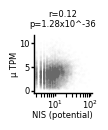

In [ ]:

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'nexons' ; Y = 'TPM'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ TPM', xlabel='n exons')
ax.set_xscale('log')
ax.legend().remove()
sns.despine()
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\np=' + f'{pval:.2}'[-1] + 'x10^-3')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'NIS' ; Y = 'TPM'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ TPM', xlabel='µ NIS')
ax.set_xscale('log')
ax.legend().remove()
sns.despine()
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'length' ; Y = 'TPM'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ TPM', xlabel='gene length')
ax.legend().remove()
sns.despine()
ax.set_xscale('log')
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
X = 'npt_isoforms' ; Y = 'TPM'
sns.scatterplot(data=mean_df, x=X, y=Y, edgecolor='None' , color='dimgrey', alpha= 0.01, s=3, ax=ax)
ax.set(ylabel='µ TPM', xlabel='NIS (potential)')
ax.legend().remove()
sns.despine()
coeff, pval = st.pearsonr(mean_df[X], mean_df[Y])
ax.set_title(f'r={format_small_number(coeff)}\n{annotpval(pval)}')
# ax.set_yticks([0,0.25,0.5,0.75,1])
ax.set_xscale('log')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
fig.savefig(pth + 'figs_intro/' + f'{Y}_{X}.scatterplot.png', format='png', dpi=300, bbox_inches='tight')

# DIV VS TPM per gene

## functions

In [ ]:


def get_gene_metrics_w0s(gene):
    ''' This function gets a gene name or gene id and returns a dataframe which contains the metrics of this gene in the readtpm_t.csv.gz, div1.csv.gz and nisoforms_expressed.csv.gz files.
    Args:
        gene: A string which is either a gene name or a gene id.
    Returns:
        A dataframe which contains the metrics of the gene in the readtpm_t.csv.gz, div1.csv.gz and nisoforms_expressed.csv.gz files. '''
    if gene[:4] != 'ENSG':
        gene = gene_info.loc[gene_info['gene_name'] == gene].index[0]

    gene_metrics = div.loc[[gene]].T # in the original function (get_gene_metrics) - the DIV=0 genes are excluded from the table. here they are included.
    gene_metrics = gene_metrics.join(metadata[['SMTS', 'SMTSD', 'system']]).dropna().rename(columns={gene: 'I-DIV'})
    gene_metrics = gene_metrics.join(nis.loc[[gene]].T).rename(columns={gene: 'NIS'})
    gene_metrics = gene_metrics.join(tpm.loc[[gene]].T).rename(columns={gene:'TPM'})
    return gene_metrics



def p_value_to_asterisks(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.01:
        return '**'
    elif p <= 0.05:
        return '*'
    else:
        return 'ns'  # Not significant
    
def filter_sample_groups(df_asterisks):
    ''' filter out tissues which have more than 50% insignificant genes '''
    drop_subts = []
    for subt in df_asterisks.columns:
        ccount = df_asterisks[subt].value_counts()
        if ccount.loc['ns'] / len(df_asterisks) > 0.25:
            drop_subts.append(subt)
    return drop_subts


def make_kmeans(df_coeff, k=4):
    kmeans = KMeans(n_clusters=k, random_state=42)
    df_coeff = df_coeff.assign(km_int = kmeans.fit_predict(df_coeff.fillna(0)   )) # zscore per gene: mean = 0, std = 1
    df_coeff.sort_values(by='km_int', inplace=True)
    df_coeff['km'] = df_coeff['km_int'].apply(lambda x: chr(ord('@')+int(x+1)))
    df_coeff.drop(columns='km_int', inplace=True)
    lut = {g: sns.color_palette("Set2", k).as_hex()[i] for i,g in enumerate(df_coeff.km.unique())}
    row_colors = df_coeff['km'].map(lut)
    return df_coeff, row_colors


def do_enrichr(glist, background_genelist, gr):
    enr = gseapy.enrichr(gene_list=glist, # or "./tests/data/gene_list.txt",
                gene_sets= ['GO_Biological_Process_2025', 'GO_Cellular_Component_2025', 'GO_Molecular_Function_2025', 'Human_Phenotype_Ontology', 'KEGG_2021_Human'],
                background=background_genelist,
                outdir=None) # don't write to disk
    enrichr_res = enr.results
    enrichr_res['-log10(Adjusted P-value)'] = -np.log10(enrichr_res['Adjusted P-value'])
    enrichr_res['-log10(P-value)'] = -np.log10(enrichr_res['P-value'])
    enrichr_res['QuerynGenes'] = len(glist)
    enrichr_res['BGnGenes'] = len(background_genelist)
    enrichr_res = enrichr_res.assign(kmcluster = gr)
    enrichr_res['nGenesTerm'] = enrichr_res.Genes.str.count(';') + 1
    # enrichr_res = enrichr_res[enrichr_res.nGenesTerm > 5]
    return enrichr_res


def do_anova(group_lists_dict):
    if len(group_lists_dict.keys()) != 4:
        raise ValueError("Should correct if there are more or less than 4 groups")
    else:
        f, p = st.f_oneway(group_lists_dict['A'].dropna(), 
                        group_lists_dict['B'].dropna(),
                        group_lists_dict['C'].dropna(), 
                        group_lists_dict['D'].dropna())
        df_between = len(group_lists_dict.keys()) - 1
        df_within = sum([len(v) for v in group_lists_dict.values()]) - len(group_lists_dict.keys())
        return f, p, df_between, df_within

## SMTS

In [ ]:
''' SMTS '''
nnow()
raw = pd.read_csv(pearson_correlations_tpm_div_path).drop_duplicates(subset='Unnamed: 0').set_index('Unnamed: 0')


SMTS_pearson_dict = {}
SMTS_pearson_dict['coeff'] = raw.filter(like = '_coeff').rename(columns=lambda x: x.replace('_coeff', ''))
SMTS_pearson_dict['pval'] = raw.filter(like = '_pval').rename(columns=lambda x: x.replace('_pval', ''))

# SMTS_pearson_dict['coeff'].to_csv(tables_main_path + 'Fig1_main.IIDV_TPM_pearsonr.csv.gz', compression='gzip', index=True)
# SMTS_pearson_dict['pval'] .to_csv(tables_main_path + 'Fig1_main.IIDV_TPM_pearsonp.csv.gz', compression='gzip', index=True)

SMTS_pearson_dict['coeff'] = SMTS_pearson_dict['coeff'].fillna(0)
SMTS_pearson_dict['pval'] = SMTS_pearson_dict['pval'].fillna(1)

SMTS_pearson_dict['*'] = SMTS_pearson_dict['pval'].map(p_value_to_asterisks).astype(str)
del raw

SMTS_pearson_dict['coeff'] = SMTS_pearson_dict['coeff'][SMTS_pearson_dict['*'] != 'ns'].fillna(0)

# drop_subts = filter_sample_groups(SMTS_pearson_dict['*'])

# for k in SMTS_pearson_dict.keys():
#     SMTS_pearson_dict[k].drop(columns=drop_subts, inplace=True)
    
ngenes  = len(SMTS_pearson_dict['coeff'])
ntissues = len(SMTS_pearson_dict['coeff'].columns)

if not os.path.isdir(pth + 'figs_intro/' + 'km_SMTS/'):
    os.mkdir(pth + 'figs_intro/' + 'km_SMTS/')



2026-09-24  16:44:41


2026-09-21  16:39:54
 
      KM cluster of Pearsons coefficients. 
      Pearsons correlations were calculated on every gene across samples with DIV>0. Tests that the number of samples were smaller than 0 were assigned as insignificant. Insignificant correlations were set to coefficient of 0 and p-value of 1.
      coefficients were clustered (ngenes=15834), using non-specific sex tissue (6 SMTS tissues). 
      (a) Heatmap: Pearson correlation coefficients of isoform diversity with gene expression, sorted by k-means (k=4) clustering of Pearsons coefficients.
      Every gene cluster was tested with overrepresentation analysis using GSEA. Background list contains all genes used for the analysis 15834 and query lists were every of the 4 clusters apart: 
      A (n=5556), B (n=1975), C (n=5802), D (n=2501)
      box plots: show the mean isoform diversity, mean gene expression, mean number of isoforms expressed, number of exons and gene length for each gene cluster.       
      


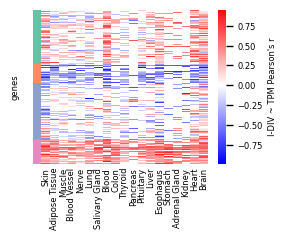

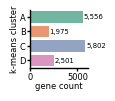

In [ ]:
nnow()
n_clusters = 4
cluster_df, row_colors = make_kmeans(SMTS_pearson_dict['coeff'].drop(columns = ['Uterus', 'Breast', 'Testis', 'Ovary', 'Vagina' ,'Prostate']), k=n_clusters)
fig, ax = plt.subplots(1, 1, figsize=( len(SMTS_pearson_dict['coeff'].columns)/ 9.3, 2))
sorted_cols = cluster_df.drop(columns=['km']).median().sort_values().index
hm_df = cluster_df.drop(columns='km')[sorted_cols]

sns.heatmap(hm_df.rename(columns={c:abb_SMTS[c] for c in hm_df.columns}), cmap='bwr', center=0, yticklabels=False, cbar_kws={'label': "I-DIV ~ TPM Pearson's r"}, ax = ax) # RdYlBu_r

ax.tick_params(axis='y', which='major', pad=20*2, length=0) # extra padding to leave room for the row colors
for i, color in enumerate(row_colors):
        ax.add_patch(plt.Rectangle(xy=(-0.05, i), width=0.05, height=1, color=color, lw=0,
                                transform=ax.get_yaxis_transform(), clip_on=False))
ax.set_ylabel('genes', labelpad=16)
cluster_palette = row_colors.to_frame(name='color').join(cluster_df['km']).drop_duplicates('km').set_index('km')['color'].to_dict()
ax.tick_params(left=False, bottom=False)
ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
fig.savefig(pth + f'figs_intro/km_SMTS/{n_clusters}kmeans_SMTS.{ngenes}genes.heatmap.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.barplot(data = cluster_df.km.value_counts().sort_index().to_frame().reset_index().rename(columns={'count': 'gene count', 'km': 'kmeans cluster'}), 
            y = 'kmeans cluster', x = 'gene count', hue = 'kmeans cluster', palette=cluster_palette, orient='h',
            dodge=False, ax=ax)
# ax.legend.remove()
ax.set_ylabel('k-means cluster')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()

for i,v in cluster_df.km.value_counts().sort_index().to_dict().items():
    plt.text(y=ord(i) - 65, x = v + 100, s=f'{v:,}', va='center', fontsize=5)
    
fig.savefig(pth + f'figs_intro/km_SMTS/barplot.png', format='png', dpi=300, bbox_inches='tight')

cluster_df = cluster_df.join(gene_info.gene_name).join(pd.Series(row_colors, name = 'color'))
cluster_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.csv.gz', compression='gzip', index=True)
# cluster_df.to_csv(tables_main_path + f'{n_clusters}kmeans_SMTS.{ngenes}genes.csv.gz', compression='gzip', index=True)
cluster_df.to_csv(supplementary_data_path + f'1e.csv.gz', compression='gzip', index=True)
enrichr_df = pd.concat([do_enrichr(glist = cluster_df.loc[cluster_df['km'] == k, 'gene_name'].to_list(), background_genelist =cluster_df.loc[:, 'gene_name'].to_list() ,gr=k )   for k in cluster_df.km.unique()])
enrichr_df.to_csv(pth + f'tables_intro/{cluster_df.km.nunique()}kmeans_SMTS.{len(cluster_df)}genes.enrichr.csv.gz', compression='gzip')
enrichr_df.to_csv(source_data_path + f'1f.csv.gz', compression='gzip', index=True)

s = f''' 
KM cluster of Pearsons coefficients. 
Pearsons correlations were calculated on every gene across samples with DIV>0. Tests that the number of samples were smaller than 0 were assigned as insignificant. Insignificant correlations were set to coefficient of 0 and p-value of 1.
coefficients were clustered (ngenes={len(cluster_df)}), using non-specific sex tissue ({metadata.loc[metadata.SMTS.isin(['Uterus', 'Breast', 'Testis', 'Ovary', 'Vagina' ,'Prostate']), 'SMTS'].nunique()} SMTS tissues). 
(a) Heatmap: Pearson correlation coefficients of isoform diversity with gene expression, sorted by k-means (k={n_clusters}) clustering of Pearsons coefficients.
Every gene cluster was tested with overrepresentation analysis using GSEA. Background list contains all genes used for the analysis {len(cluster_df)} and query lists were every of the 4 clusters apart: 
A (n={len(cluster_df[cluster_df.km=='A'])}), B (n={len(cluster_df[cluster_df.km=='B'])}), C (n={len(cluster_df[cluster_df.km=='C'])}), D (n={len(cluster_df[cluster_df.km=='D'])})

'''

with open(pth + f'figs_intro/km_SMTS/about.txt', 'w') as f:
    f.write(s)
    f.close()


### examples for clusters

In [29]:
# cluster_df = pd.read_csv(pth + f'tables_intro/{cluster_df.km.nunique()}kmeans_SMTS.{len(cluster_df)}genes.csv.gz', compression='gzip', index_col=0)
# enrichr_df = pd.read_csv(pth + f'tables_intro/{cluster_df.km.nunique()}kmeans_SMTS.{len(cluster_df)}genes.enrichr.csv.gz', compression='gzip')
# cluster_palette = cluster_df.drop_duplicates('km').set_index('km')['color'].to_dict()
# n_clusters = cluster_df.km.nunique()
# ngenes = len(cluster_df)

 gene MYO18A
Example of gene found at SMTS Heart
from cluster: D
(b) Scatterplot: Every datapoint is a sample (n=225). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (9), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=9
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=9
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.4987328990039378
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.3111967426592394
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isof

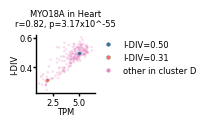

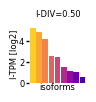

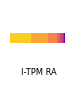

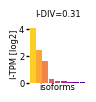

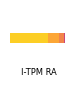

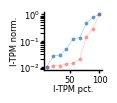

In [ ]:
# t = 'Heart' ; nnis = 9 # 7 9 12
# gid = 'ENSG00000196535' ; gn = gene_info.loc[gid, 'gene_name']

# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.index]



# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_min,nnis_max])}

# gn = gene_info.loc[gid, 'gene_name']
# fig, ax = plt.subplots(figsize=(0.75,0.75))
# sns.scatterplot(data = gene_metrics[(gene_metrics.SMTS == t) ], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)

# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster D')
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTS_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTS/' + gn + f'.scatter.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTS')
# isoform_expression_barplots(smpl=nnis_min, isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTS')

# # isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, info=f'', o='km_SMTS')
# isoform_expression_lineplot(spl_min=nnis_max, spl_max=nnis_min, gn=gn, n_nis=nnis, savefig=True, o='km_SMTS')


# s=f''' gene {gn}
# Example of gene found at SMTS {t}
# number of isoforms in examples: {nnis}
# from cluster: {cluster_df.loc[gid, 'km']}
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']}
# '''

# with open(pth + f'figs_intro/km_SMTS/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()

 gene SND1
Example of gene found at SMTS Skin
from cluster: B
(b) Scatterplot: Every datapoint is a sample (n=527). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (5), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=5
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=5
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.3426400722111288
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.0714134045240037
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform

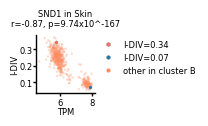

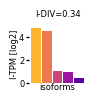

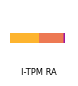

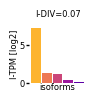

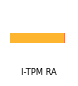

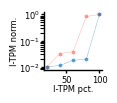

In [ ]:
# t = 'Skin' ; nnis = 5
# gid = 'ENSG00000197157' ; gn = gene_info.loc[gid, 'gene_name']

# gene_metrics = get_gene_metrics(gene=gid)# [metadata[metadata.SMTS == t].index]
# gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]

# isoforms_df = get_isoforms_from_gene(gene=gid)[gene_metrics[gene_metrics.SMTS == t].index]
# isoforms_df = isoforms_df[gene_metrics[gene_metrics.SMTS == t].index]

# gn = gene_info.loc[gid, 'gene_name']
# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# # nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()
# nnis_min = 'GTEX-1GN1V-0008-SM-EAZD5'

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}


# fig, ax = plt.subplots(figsize=(0.75,0.75))

# sns.scatterplot(data = gene_metrics[(gene_metrics.SMTS == t) ], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)

# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster B')
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTS_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTS/' + gn + f'.scatter.png', format='png', dpi=300, bbox_inches='tight')

# gene_metrics = get_gene_metrics(gene=gid)# [metadata[metadata.SMTS == t].index]
# gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTS')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTS')

# isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTS')

# s=f''' gene {gn}
# Example of gene found at SMTS {t}
# from cluster: {cluster_df.loc[gid, 'km']}
# number of isoforms in examples: {nnis}
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''


# with open(pth + f'figs_intro/km_SMTS/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()

### cluster general metrics

In [ ]:
# cluster_df = pd.read_csv(pth + f'tables_intro/4kmeans_SMTS.15834genes.csv.gz', index_col='Unnamed: 0')
# cluster_df

,Skin,Adipose Tissue,Muscle,Blood Vessel,Nerve,Heart,Lung,Salivary Gland,Brain,Blood,...,Pituitary,Esophagus,Colon,Liver,Adrenal Gland,Stomach,Kidney,km,gene_name,color
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
ENSG00000168116,0.150930,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.421218,0.215140,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,A,KIAA1586,#66c2a5
ENSG00000205084,0.144689,0.256930,0.224792,0.000000,0.000000,0.484953,0.000000,0.000000,0.318416,0.609213,...,0.000000,0.297107,0.000000,0.301763,0.000000,0.455308,0.000000,A,TMEM231,#66c2a5
ENSG00000184860,0.760836,0.160636,0.000000,0.273694,0.000000,0.372932,0.191378,0.000000,0.197233,0.487285,...,-0.216508,0.154938,0.000000,0.000000,0.000000,0.000000,0.000000,A,SDR42E1,#66c2a5
ENSG00000140945,0.500093,0.121777,0.000000,0.000000,0.000000,0.493177,0.000000,0.000000,0.123448,0.247592,...,0.184429,0.227710,0.000000,0.310630,0.356167,0.000000,0.465235,A,CDH13,#66c2a5
ENSG00000137251,0.000000,0.000000,-0.330599,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.602914,...,0.000000,0.000000,0.636859,0.000000,0.000000,0.000000,0.000000,A,TINAG,#66c2a5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000241484,0.698128,0.472342,0.266875,0.403556,0.000000,0.419054,0.433339,0.446489,0.325345,0.351710,...,0.270054,0.749747,0.576912,0.387238,0.344807,0.742177,0.000000,D,ARHGAP8,#e78ac3
ENSG00000185666,0.400107,0.119552,0.170562,0.275386,0.000000,0.299445,0.336373,0.386779,-0.295443,0.560948,...,0.166524,0.379978,0.000000,0.370855,0.000000,0.000000,0.000000,D,SYN3,#e78ac3
ENSG00000100335,0.416506,0.000000,0.171907,0.218450,0.248733,0.343688,0.000000,0.496506,0.580637,0.553957,...,0.000000,0.333437,0.225874,0.374295,0.352964,0.000000,0.471350,D,MIEF1,#e78ac3


In [14]:
colname = 'TPM [log] mean'
boxplot_df = tpm[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns=['km', 'gene_name', 'color']).columns)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
colname = 'DIV mean'
boxplot_df = boxplot_df.join(div[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns=['km', 'gene_name', 'color']).columns)].index)].mean(axis = 'columns').to_frame(name=colname))
colname = 'NIS mean'
boxplot_df = nis[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns=['km', 'gene_name', 'color']).columns)].index)].mean(axis = 'columns').to_frame(name=colname)
colname = 'nexons'
boxplot_df = boxplot_df.join(gene_info)
boxplot_df = boxplot_df.join(pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTS_wo_sext/div_nis.pearson.csv', index_col='Unnamed: 0').add_suffix('_DIV_NIS'))
boxplot_df = boxplot_df.join(pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTS_wo_sext/nis_tpm.pearson.csv', index_col='Unnamed: 0').add_suffix('_TPM_NIS'))
boxplot_df = boxplot_df.join(pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTS_wo_sext/div_tpm.pearson.csv', index_col='Unnamed: 0').add_suffix('_TPM_DIV'))
boxplot_df.to_csv(source_data_path + f'S2c.csv.gz', compression='gzip', index=True)


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 190.27, df between = 3, df within = 15830, p=3.20e-121  
    


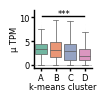

In [ ]:
# boxplot_df = tpm.join(cluster_df.km).dropna(subset=['km'])[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns='km').columns)].index) + ['km']]
# boxplot_df = boxplot_df.melt(id_vars='km', var_name='sample', value_name='TPM')
colname = 'TPM [log] mean'
boxplot_df = tpm[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns=['km', 'gene_name', 'color']).columns)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.mtpm.csv.gz', compression='gzip', index=True)
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=boxplot_df, x='km', y=colname, palette=cluster_palette, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel='k-means cluster', ylabel = 'µ TPM')
sns.despine()
# ax.set_ylim(-5, ax.set_ylim()[1])

f, p, df_between, df_within = do_anova(group_lists_dict = {k: boxplot_df.loc[boxplot_df.km == k, colname] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)

ax.axhline(y = 10.25, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=10.25, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)

fig.savefig(pth + f'figs_intro/km_SMTS/mtpm.boxplot.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/mtpm.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 1200.21, df between = 3, df within = 15830, p<10^-323  
    


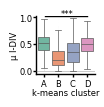

In [ ]:
# boxplot_df = tpm.join(cluster_df.km).dropna(subset=['km'])[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns='km').columns)].index) + ['km']]
# boxplot_df = boxplot_df.melt(id_vars='km', var_name='sample', value_name='TPM')
colname = 'DIV mean'
boxplot_df = div[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns=['km', 'gene_name', 'color']).columns)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.midiv.csv.gz', compression='gzip', index=True)
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=boxplot_df, x='km', y=colname, palette=cluster_palette, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel='k-means cluster', ylabel = 'µ I-DIV')
sns.despine()
# ax.set_ylim(-5, ax.set_ylim()[1])

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: boxplot_df.loc[boxplot_df.km == k, colname] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)
ax.axhline(y = 1.02, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=1.02, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)

fig.savefig(pth + f'figs_intro/km_SMTS/midiv.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/{colname.replace(' ', '')}.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 552.68, df between = 3, df within = 15830, p<10^-323  
    


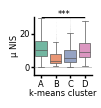

In [ ]:
# boxplot_df = tpm.join(cluster_df.km).dropna(subset=['km'])[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns='km').columns)].index) + ['km']]
# boxplot_df = boxplot_df.melt(id_vars='km', var_name='sample', value_name='TPM')
colname = 'NIS mean'
boxplot_df = nis[ list(metadata.loc[metadata.SMTS.isin(cluster_df.drop(columns=['km', 'gene_name', 'color']).columns)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.mnis.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=boxplot_df, x='km', y=colname, palette=cluster_palette, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel='k-means cluster', ylabel = 'µ NIS')
sns.despine()
ax.set_ylim(ax.set_ylim()[0], 15.1)

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: boxplot_df.loc[boxplot_df.km == k, colname] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)
ax.axhline(y = 15.05, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=15.05, x = 1.15, s = p_value_to_asterisks(p))
fig.savefig(pth + f'figs_intro/km_SMTS/{colname}.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/{colname}.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 794.76, df between = 3, df within = 15830, p<10^-323  
    


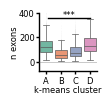

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))

colname = 'nexons'
boxplot_df = gene_info.join(cluster_df.km)
boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.nexons_and_glength.csv.gz', compression='gzip', index=True)
sns.boxplot(data=boxplot_df.dropna(subset=['km']), 
            x='km', y=colname, palette=cluster_palette, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1},
            fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel='k-means cluster', ylabel='n exons')
sns.despine()
ax.set_ylim(ax.set_ylim()[0], 100)

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: gene_info.join(cluster_df.km).loc[gene_info.join(cluster_df.km).km == k, colname] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)

ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)
ax.axhline(y = 90, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=90, x = 1.15, s = p_value_to_asterisks(p))


fig.savefig(pth + f'figs_intro/km_SMTS/{colname}.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/{colname}.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 32.14, df between = 3, df within = 15830, p=1.06e-20  
    


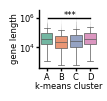

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
colname = 'length'

sns.boxplot(data=boxplot_df.dropna(subset=['km']), 
            x='km', y=colname, palette=cluster_palette, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1},
            fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel='k-means cluster', ylabel='gene length')
sns.despine()
ax.set_yscale('log')

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: gene_info.join(cluster_df.km).loc[gene_info.join(cluster_df.km).km == k, colname] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)
ax.axhline(y = 10**6, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=10**6, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)

fig.savefig(pth + f'figs_intro/km_SMTS/glength.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/g{colname}.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 735.44, df between = 3, df within = 15830, p<10^-323  
    


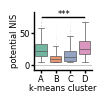

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
colname = 'npt_isoforms'

sns.boxplot(data=boxplot_df.dropna(subset=['km']), 
            x='km', y=colname, palette=cluster_palette, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1},
            fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set(xlabel='k-means cluster', ylabel='potential NIS')
sns.despine()
ax.set_ylim(ax.set_ylim()[0], 33)

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: gene_info.join(cluster_df.km).loc[gene_info.join(cluster_df.km).km == k, colname] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)

ax.axhline(y = 30, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=30, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)

fig.savefig(pth + f'figs_intro/km_SMTS/{colname}.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/{colname}.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 2642.08, df between = 3, df within = 15830, p<10^-323  
    


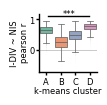

In [ ]:
df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTS_wo_sext/div_nis.pearson.csv')
df = df[df.coeff != 'coeff']
df.coeff = df.coeff.astype(float)
df.pval = df.pval.astype(float)
df.drop_duplicates(subset=['Unnamed: 0'], inplace=True)
df.set_index('Unnamed: 0', inplace=True)
df = df.join(cluster_df.km.to_frame())

df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.r_DIV_NIS.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=df, x='km', y='coeff', palette=cluster_palette,
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
            fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
ax.set(ylabel='I-DIV ~ NIS\npearson r', xlabel='k-means cluster')
sns.despine()
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'coeff'] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)
ax.axhline(y = 1.1, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=1.1, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)


fig.savefig(pth + f'figs_intro/km_SMTS/r_DIV_NIS.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/r_DIV_NIS.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 1077.66, df between = 3, df within = 15830, p<10^-323  
    


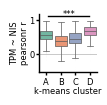

In [ ]:
df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTS_wo_sext/nis_tpm.pearson.csv')
df = df[df.coeff != 'coeff']
df.coeff = df.coeff.astype(float)
df.pval = df.pval.astype(float)
df.drop_duplicates(subset=['Unnamed: 0'], inplace=True)
df.set_index('Unnamed: 0', inplace=True)
# df = df.assign(mean_nis = nis.mean(axis='columns'))
df = df.join(cluster_df.km.to_frame())

df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.r_TPM_NIS.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=df, x='km', y='coeff', palette=cluster_palette,
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
            fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
ax.set(ylabel='TPM ~ NIS\npearsonr r', xlabel='k-means cluster')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'coeff'] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)

ax.axhline(y = 1.1, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=1.1, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)


fig.savefig(pth + f'figs_intro/km_SMTS/r_TPM_NIS.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/r_TPM_NIS.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 7520.32, df between = 3, df within = 15830, p<10^-323  
    


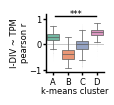

In [ ]:
df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTS_wo_sext/div_tpm.pearson.csv')
df = df[df.coeff != 'coeff']
df.coeff = df.coeff.astype(float)
df.pval = df.pval.astype(float)
df.drop_duplicates(subset=['Unnamed: 0'], inplace=True)
df.set_index('Unnamed: 0', inplace=True)
df = df.join(cluster_df.km.to_frame())

df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.r_DIV_TPM.csv.gz', compression='gzip', index=True)


fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=df, x='km', y='coeff', palette=cluster_palette,
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
            fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
ax.set(ylabel='I-DIV ~ TPM\npearson r', xlabel='k-means cluster')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'coeff'] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)
ax.axhline(y = 1.1, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=1.1, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)


fig.savefig(pth + f'figs_intro/km_SMTS/r_DIV_TPM.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/r_DIV_TPM.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of what is described in the file name. 
    F = 933.93, df between = 3, df within = 15830, p<10^-323  
    


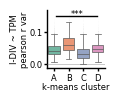

In [ ]:
df = cluster_df.drop(columns=['km', 'gene_name', 'color']).var(axis='columns').to_frame(name='var').join(cluster_df.km)
df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTS.{ngenes}genes.var_coeff.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.boxplot(data=df, x='km', y='var', palette=cluster_palette,
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
            fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
ax.set(ylabel='I-DIV ~ TPM\npearson r var', xlabel='k-means cluster')
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()

f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'var'] for k in cluster_df.km.unique()})
s = f'''
    one-way ANOVA test for the effect of what is described in the file name. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
print(s)
ax.axhline(y = 0.15, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
ax.text(y=0.15, x = 1.15, s = p_value_to_asterisks(p))
ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)
ax.set_ylim(ax.get_ylim()[0], 0.17)

fig.savefig(pth + f'figs_intro/km_SMTS/var_coeff.png', format='png', dpi=300, bbox_inches='tight')
with open(pth + f'figs_intro/km_SMTS/var_coeff.about.txt', 'w') as file:
    file.write(s)
    file.close()

### enrichment analysis

In [9]:
pth = '/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/downstream_results/'

In [ ]:
# cluster_df = pd.read_csv(f'tables_intro/4kmeans_SMTS.15834genes.csv.gz', compression='gzip', index_col=0)
# enrichr_df = pd.read_csv(f'tables_intro/4kmeans_SMTS.15834genes.enrichr.csv.gz', compression='gzip')
# cluster_palette = cluster_df.drop_duplicates('km').set_index('km')['color'].to_dict()
# n_clusters = cluster_df.km.nunique()
# ngenes = len(cluster_df)
# gs = 'GO_Biological_Process_2025'
# enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)


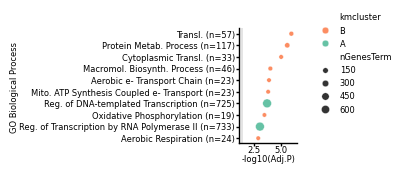

In [10]:
label_abbrev = {
    "Translation (n=57)": "Translation (n=57)",
    "Protein Metabolic Process (n=117)": "Protein Metab. Process (n=117)",
    "Cytoplasmic Translation (n=33)": "Cytoplasmic Transl. (n=33)",
    "Macromolecule Biosynthetic Process (n=46)": "Macromol. Biosynth. Process (n=46)",
    "Aerobic Electron Transport Chain (n=23)": "Aerobic e- Transport Chain (n=23)",
    "Mitochondrial ATP Synthesis Coupled Electron Transport (n=23)": "Mito. ATP Synthesis-Coupled e- Transport (n=23)",
    "Regulation of DNA-templated Transcription (n=725)": "Reg. of DNA-templated Transcript. (n=725)",
    "Oxidative Phosphorylation (n=19)": "Oxidative Phosphorylation (n=19)",
    "Regulation of Transcription by RNA Polymerase II (n=733)": "Reg. of Transcript. by RNA Pol II (n=733)",
    "Aerobic Respiration (n=24)": "Aerobic Respiration (n=24)",
}

gs = 'GO_Biological_Process_2025'
enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)

fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/6.7))
sns.scatterplot(data = enrichr_tmp_df, 
            x = '-log10(Adjusted P-value)', y = 'Term', hue = 'kmcluster', palette=cluster_palette, 
            size='nGenesTerm', sizes=(10,40), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)

labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)

ax.set(ylabel='Biological Process')

# ax.legend().remove()
ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)
ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels([label_abbrev[t.get_text()] for t in ax.get_yticklabels()],x=0.07)
ax.set_yticklabels([t.get_text().replace('Metabolic', 'Metab.').replace('Translation', 'Transl.').replace('Macromolecule Biosynthetic', 'Macromol. Biosynth.').replace('Electron', 'e-').replace('Mitochondrial', 'Mito.').replace('Regulation', 'Reg.') for t in ax.get_yticklabels()],x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()
fig.savefig(pth + f'figs_intro/km_SMTS/enrichr.png', format='png', dpi=300, bbox_inches='tight')

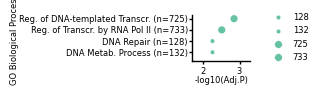

In [11]:
kmcluster_ = 'A'    

label_abbrev = {
    "Regulation of DNA-templated Transcription (n=725)": "Reg. of DNA-templated Transcr. (n=725)",
    "Regulation of Transcription by RNA Polymerase II (n=733)": "Reg. of Transcr. by RNA Pol II (n=733)",
    "DNA Repair (n=128)": "DNA Repair (n=128)",
    "DNA Metabolic Process (n=132)": "DNA Metab. Process (n=132)",
}

enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)

fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/6.7))
sns.scatterplot(data = enrichr_tmp_df, 
            x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
            size='nGenesTerm', sizes=(10,30), ax=ax, zorder = 5)

labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)
# ax.legend().remove()
ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)
ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')

ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels([label_abbrev[y.get_text()]  for y in ax.get_yticklabels()],x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
ax.set_xlim(ax.set_xlim()[0] * 1.2,ax.set_xlim()[1] * 1.2  )
ax.set_ylim(ax.set_ylim()[0] * 1.2,ax.set_ylim()[1] * 2.2  )
sns.despine()


fig.savefig(pth + f'figs_intro/km_SMTS/enrichr.{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

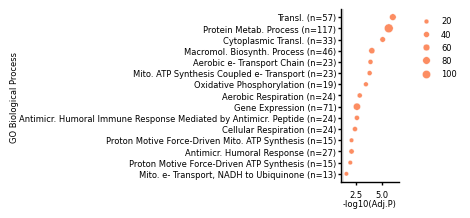

In [16]:
kmcluster_ = 'B'
label_abbrev = {
    "Translation (n=57)": "Transl. (n=57)",
    "Protein Metabolic Process (n=117)": "Protein Metab. Process (n=117)",
    "Cytoplasmic Translation (n=33)": "Cytoplasmic Transl. (n=33)",
    "Macromolecule Biosynthetic Process (n=46)": "Macromol. Biosynth. Process (n=46)",
    "Aerobic Electron Transport Chain (n=23)": "Aerobic e- Transport Chain (n=23)",
    "Mitochondrial ATP Synthesis Coupled Electron Transport (n=23)": "Mito. ATP Synthesis Coupled e- Transport (n=23)",
    "Oxidative Phosphorylation (n=19)": "Oxidative Phosphorylation (n=19)",
    "Aerobic Respiration (n=24)": "Aerobic Respiration (n=24)",
    "Gene Expression (n=71)": "Gene Expression (n=71)",
    "Antimicrobial Humoral Immune Response Mediated by Antimicrobial Peptide (n=24)": "Antimicr. Humoral Immune Response Mediated by Antimicr. Peptide (n=24)",
    "Cellular Respiration (n=24)": "Cellular Respiration (n=24)",
    "Proton Motive Force-Driven Mitochondrial ATP Synthesis (n=15)": "Proton Motive Force-Driven Mito. ATP Synthesis (n=15)",
    "Antimicrobial Humoral Response (n=27)": "Antimicr. Humoral Response (n=27)",
    "Proton Motive Force-Driven ATP Synthesis (n=15)": "Proton Motive Force-Driven ATP Synthesis (n=15)",
    "Mitochondrial Electron Transport, NADH to Ubiquinone (n=13)": "Mito. e- Transport, NADH to Ubiquinone (n=13)",
}

enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)

fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/6.7))
sns.scatterplot(data = enrichr_tmp_df, 
            x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
            size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5)
labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)
# ax.legend().remove()
ax.legend(bbox_to_anchor = (1.2,1), frameon=False)
ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels([label_abbrev[y.get_text()]  for y in ax.get_yticklabels()],x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()
fig.savefig(pth + f'figs_intro/km_SMTS/enrichr.{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


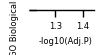

In [ ]:
kmcluster_ = 'C'

    
enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)
if len(enrichr_tmp_df) > 0:
    fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/5))
    sns.scatterplot(data = enrichr_tmp_df, 
                x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
                size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5).grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
    labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
    labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
    ax.set_yticklabels(labels)
    ax.legend().remove()
    ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
    ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
    ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
    sns.despine()
    fig.savefig(pth + f'figs_intro/enrichr.{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


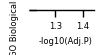

In [ ]:
kmcluster_ = 'D'    
enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)
if len(enrichr_tmp_df) > 0:
    fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/5))
    sns.scatterplot(data = enrichr_tmp_df, 
                x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
                size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5).grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
    labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
    labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
    ax.set_yticklabels(labels)
    ax.legend().remove()
    ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
    ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
    ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
    sns.despine()
    fig.savefig(pth + f'figs_intro/km_SMTS/enrichr.{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

### examples of genes from specific GO terms

In [48]:
k = 'B'
gs = 'GO_Biological_Process_2025'
tm = 'Translation (GO:0006412)'
gns = enrichr_df.loc[(enrichr_df.Gene_set == gs) & (enrichr_df.Term == tm) & (enrichr_df.kmcluster == k), 'Genes'].values[0].split(';')
minvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns=['km', 'color', 'gene_name']).idxmin().to_dict()
minvals

{'Skin': 'ENSG00000197728',
 'Adipose Tissue': 'ENSG00000197728',
 'Muscle': 'ENSG00000197728',
 'Blood Vessel': 'ENSG00000140986',
 'Nerve': 'ENSG00000197728',
 'Heart': 'ENSG00000140986',
 'Lung': 'ENSG00000197728',
 'Salivary Gland': 'ENSG00000197728',
 'Brain': 'ENSG00000167658',
 'Blood': 'ENSG00000110700',
 'Thyroid': 'ENSG00000197728',
 'Pancreas': 'ENSG00000156508',
 'Pituitary': 'ENSG00000197728',
 'Esophagus': 'ENSG00000140986',
 'Colon': 'ENSG00000197728',
 'Liver': 'ENSG00000197728',
 'Adrenal Gland': 'ENSG00000156508',
 'Stomach': 'ENSG00000197728',
 'Kidney': 'ENSG00000167658'}


Example of gene found at 
cluster: B
gene set: GO Biological Process 2025
enriched term: Translation (GO:0006412) – RPS13 gene.
(b) Scatterplot: Every datapoint is a sample (n=245). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (9), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=9
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=9
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.54
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.14
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagon

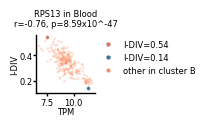

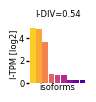

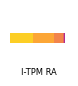

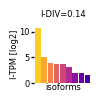

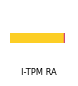

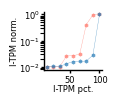

In [ ]:
t = 'Blood'
gid = minvals[t] ; gn = gene_info.loc[gid, 'gene_name']
nnis = 9 # 7 9 10
iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])

gene_metrics = get_gene_metrics(gene=gid)
gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]
isoforms_df = get_isoforms_from_gene(gene=gid)
isoforms_df = isoforms_df[gene_metrics[gene_metrics.SMTS == t].index]

isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
isoforms_df.to_csv(source_data_path + f'1g.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)
gene_metrics.to_csv(source_data_path + f'1g_topleft.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.scatterplot(data = gene_metrics[(gene_metrics.SMTS == t) ], x = 'TPM', y = 'I-DIV', 
                edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)
ax.set_title(' in '.join([gene_info.loc[gid, 'gene_name'], t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTS_pearson_dict['pval'].loc[gid, t])]))

nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}
for c in [nnis_max,nnis_min]:
    sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
                edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)


legend_handles = [
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
           markeredgecolor='none', markersize=3, label='other in cluster B')
]
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,annotpval(SMTS_pearson_dict['pval'].loc[gid, t])]))
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()
fig.savefig(pth + 'figs_intro/km_SMTS/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

isoform_expression_barplots(smpl=nnis_max, 
                            isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTS')
isoform_expression_barplots(smpl=nnis_min, 
                            isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTS')

isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTS')

s = f'''
Example of gene found at 
cluster: {k}
gene set: {gs.replace('_', ' ')}
enriched term: {tm} – {gn} gene.
(b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
(d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
'''
with open(pth + 'figs_intro/km_SMTS/' + f'{gn}.about.txt', 'w') as f: 
    f.write(s)
    f.close()

In [50]:
k = 'B'
gs = 'GO_Biological_Process_2025'
tm = 'Gene Expression (GO:0010467)'
gns = enrichr_df.loc[(enrichr_df.Gene_set == gs) & (enrichr_df.Term == tm) & (enrichr_df.kmcluster == k), 'Genes'].values[0].split(';')
minvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns = ['km', 'color', 'gene_name']).idxmin().to_dict()
minvals

{'Skin': 'ENSG00000140943',
 'Adipose Tissue': 'ENSG00000197728',
 'Muscle': 'ENSG00000197728',
 'Blood Vessel': 'ENSG00000140986',
 'Nerve': 'ENSG00000197728',
 'Heart': 'ENSG00000140986',
 'Lung': 'ENSG00000197540',
 'Salivary Gland': 'ENSG00000092009',
 'Brain': 'ENSG00000100448',
 'Blood': 'ENSG00000113088',
 'Thyroid': 'ENSG00000197540',
 'Pancreas': 'ENSG00000156508',
 'Pituitary': 'ENSG00000197728',
 'Esophagus': 'ENSG00000165799',
 'Colon': 'ENSG00000092009',
 'Liver': 'ENSG00000179218',
 'Adrenal Gland': 'ENSG00000156508',
 'Stomach': 'ENSG00000124788',
 'Kidney': 'ENSG00000110700'}


Example of gene found at 
cluster: B
gene set: GO Biological Process 2025
enriched term: Gene Expression (GO:0010467) – ATXN1 gene.
(b) Scatterplot: Every datapoint is a sample (n=27). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (9), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=9
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=9
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.87
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.56
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexa

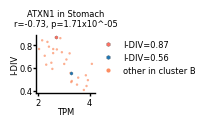

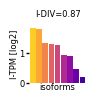

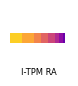

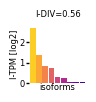

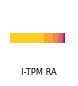

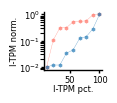

In [ ]:
# t = 'Stomach' 
# gid = minvals[t] ; gn = gene_info.loc[gid, 'gene_name']
# nnis = 9 # 7 9 10
# iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])

# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics[gene_metrics.SMTS == t].index]

# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}

# fig, ax = plt.subplots(figsize=(0.75,0.75))

# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.7)
# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTS_pearson_dict['pval'].loc[gid, t])]))

# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster ' + k)
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# fig.savefig(pth + 'figs_intro/km_SMTS/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTS')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTS')

# isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTS')

# s = f'''{gn}
# cluster: {k}
# gene set: {gs.replace('_', ' ')}
# enriched term: {tm} – {gn} gene.
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''

# with open(pth + f'figs_intro/km_SMTS/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()

# nnow()

In [ ]:
# gene_info = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.3/gene_metadata.csv.gz', index_col=0)
# metadata = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.5/other_and_HK-RP/metadata.csv.gz', index_col=0)


Blood ENSG00000171469 ZNF561

Example of gene found at 
cluster: A
gene set: GO Biological Process 2025
enriched term: TrnReg – ZNF561 gene.
(b) Scatterplot: Every datapoint is a sample (n=244). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (8), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=8
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=8
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.66
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.45
(e) lineplot: shows isoform expression, shown on scaled 

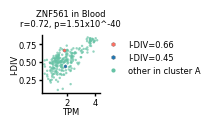

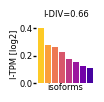

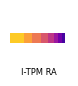

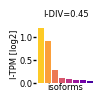

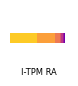

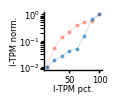

In [ ]:
k = 'A'
gs = 'GO_Biological_Process_2025'
tm = 'TrnReg'
enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
l1 = enrichr_tmp_df.loc[(enrichr_tmp_df['kmcluster'] == k) & (enrichr_tmp_df['Term'] == 'Regulation of DNA-templated Transcription (GO:0006355)')].Genes.str.split(';')[0]
l2 = enrichr_tmp_df.loc[(enrichr_tmp_df['kmcluster'] == k) & (enrichr_tmp_df['Term'] == 'Regulation of Transcription by RNA Polymerase II (GO:0006357)')].Genes.str.split(';').values[0]
gns = np.intersect1d(l1,l2)
maxvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns = ['km', 'color', 'gene_name']).idxmax().to_dict()
t = 'Blood'
# gid = maxvals[t]
gid = 'ENSG00000171469'
# t = cluster_df.loc[cluster_df.gene_name.isin(gns) ].drop(columns=['km', 'gene_name', 'color']).idxmax(axis='rows').idxmax()
# gid = cluster_df.loc[cluster_df.gene_name.isin(gns) ].drop(columns=['km', 'gene_name', 'color']).idxmax(axis='columns').idxmax()
gn = gene_info.loc[gid, 'gene_name']
print(t, gid, gn)

# t = 'Stomach' 
# gid = minvals[t] ; gn = gene_info.loc[gid, 'gene_name']
nnis = 8 # 5 6 7 8 9 10
iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])

gene_metrics = get_gene_metrics(gene=gid)
gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]
isoforms_df = get_isoforms_from_gene(gene=gid)
isoforms_df = isoforms_df[gene_metrics[gene_metrics.SMTS == t].index]

isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(source_data_path + f'1h.csv.gz', compression='gzip', index=True)
nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}

fig, ax = plt.subplots(figsize=(0.75,0.75))

sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
                edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.7)
for c in [nnis_max,nnis_min]:
    sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
                edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,annotpval(SMTS_pearson_dict['pval'].loc[gid, t])]))

legend_handles = [
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
           markeredgecolor='none', markersize=3, label='other in cluster ' + k)
]
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()

fig.savefig(pth + 'figs_intro/km_SMTS/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

isoform_expression_barplots(smpl=nnis_max, 
                            isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTS')
isoform_expression_barplots(smpl=nnis_min, 
                            isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTS')

isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTS')

s=f'''
Example of gene found at 
cluster: {k}
gene set: {gs.replace('_', ' ')}
enriched term: {tm} – {gn} gene.
(b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
(d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
'''
with open(pth + f'figs_intro/km_SMTS/{gn}.about.txt', 'w') as f:
    f.write(s)
    f.close()
nnow()

Blood ENSG00000077684 JADE1
2026-09-24  17:01:12


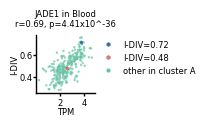

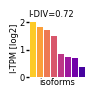

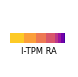

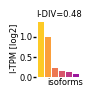

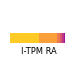

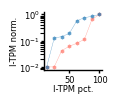

In [ ]:
k = 'A'
gs = 'GO_Biological_Process_2025'
tm = 'TrnReg'
enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
l1 = enrichr_tmp_df.loc[(enrichr_tmp_df['kmcluster'] == k) & (enrichr_tmp_df['Term'] == 'Regulation of DNA-templated Transcription (GO:0006355)')].Genes.str.split(';')[0]
l2 = enrichr_tmp_df.loc[(enrichr_tmp_df['kmcluster'] == k) & (enrichr_tmp_df['Term'] == 'Regulation of Transcription by RNA Polymerase II (GO:0006357)')].Genes.str.split(';').values[0]
gns = np.intersect1d(l1,l2)
maxvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns = ['km', 'color', 'gene_name']).idxmax().to_dict()
t = 'Blood'
gid = 'ENSG00000077684'
gn = gene_info.loc[gid, 'gene_name']
print(t, gid, gn)

nnis = 8 # 5 6 7 8 9 10
iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])

gene_metrics = get_gene_metrics(gene=gid)
gene_metrics = gene_metrics.loc[gene_metrics.SMTS == t]
isoforms_df = get_isoforms_from_gene(gene=gid)
isoforms_df = isoforms_df[gene_metrics[gene_metrics.SMTS == t].index]

# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)
isoforms_df.to_csv(source_data_path + f'1h.{gn}.csv.gz', compression='gzip', index=True)
gene_metrics.to_csv(source_data_path + f'1h_topleft.csv.gz', compression='gzip', index=True)

nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

c_palette = {c: s_colors[i] for i, c in enumerate([nnis_min,nnis_max])}

fig, ax = plt.subplots(figsize=(0.75,0.75))

sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
                edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.7)
for c in [nnis_max,nnis_min]:
    sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
                edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTS_pearson_dict['coeff'].loc[gid, t]:.2f}' ,annotpval(SMTS_pearson_dict['pval'].loc[gid, t])]))

legend_handles = [
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=c_palette[nnis_max],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
    Line2D([], [], marker='h', linestyle='None', markerfacecolor=c_palette[nnis_min],markeredgewidth=0.25,
           markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
    Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
           markeredgecolor='none', markersize=3, label='other in cluster ' + k)
]
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
ax.tick_params(length=2.5) ## other options are right and top
ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
ax.set_xlabel(ax.get_xlabel(),labelpad=0)
ax.set_ylabel(ax.get_ylabel(),labelpad=0)
sns.despine()

fig.savefig(pth + 'figs_intro/km_SMTS/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

isoform_expression_barplots(smpl=nnis_max, 
                            isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTS')
isoform_expression_barplots(smpl=nnis_min, 
                            isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTS')

isoform_expression_lineplot(spl_min=nnis_max, spl_max=nnis_min, gn=gn, n_nis=nnis, savefig=True, o='km_SMTS')

s=f'''
Example of gene found at 
cluster: {k}
gene set: {gs.replace('_', ' ')}
enriched term: {tm} – {gn} gene.
(b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
(d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
'''

nnow()

with open(pth + f'figs_intro/km_SMTS/{gn}.about.txt', 'w') as f:
    f.write(s)
    f.close()

## SMTSD only in brain regions

In [ ]:
# raw = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/div_tpm/SMTSD.pearson.csv').drop_duplicates(subset='Unnamed: 0').set_index('Unnamed: 0')

# SMTSD_pearson_dict = {}
# SMTSD_pearson_dict['coeff'] = raw.filter(like = '_coeff').filter(like='Brain').rename(columns=lambda x: x.replace('_coeff', '').replace('Brain - ', ''))
# SMTSD_pearson_dict['coeff'].fillna(0, inplace=True)
# SMTSD_pearson_dict['pval'] = raw.filter(like = '_pval').filter(like='Brain').rename(columns=lambda x: x.replace('_pval', '').replace('Brain - ', ''))
# SMTSD_pearson_dict['pval'].fillna(1, inplace=True)

# SMTSD_pearson_dict['*'] = SMTSD_pearson_dict['pval'].map(p_value_to_asterisks).astype(str)
# del raw

# ngenes  = len(SMTSD_pearson_dict['coeff'])
# ntissues = len(SMTSD_pearson_dict['coeff'].columns)


# if not os.path.isdir(pth + 'figs_intro/km_SMTSD_brain/'):
#     os.mkdir(pth + 'figs_intro/km_SMTSD_brain/')

# nnow()

NameError: name 'p_value_to_asterisks' is not defined

2026-09-14  09:48:06
      
      choosing number of clusters for kmeans clustering. Using Inertia, distortion and silhouette scores.
      


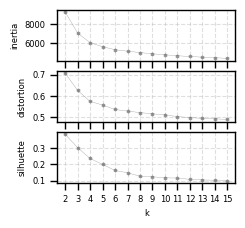

In [ ]:
# res = choose_k(df=SMTSD_pearson_dict['coeff'], filename='SMTSD_brain_kselection')
# res.to_csv(pth + 'tables_intro/' + 'SMTSD_brain.choose_k.csv.gz', compression='gzip', index=True)
# nnow()

# print(f'''      
#       choosing number of clusters for kmeans clustering. Using Inertia, distortion and silhouette scores.
#       ''')


 
      KM cluster of Pearsons coefficients. 
      Pearsons correlations were calculated on every gene across samples with DIV>0. Tests that the number of samples were smaller than 0 were assigned as insignificant. Insignificant correlations were set to coefficient of 0 and p-value of 1.
      coefficients were clustered (ngenes=15834), using SMTSD tissues from brain (13 SMTSD tissues). 
      (a) Heatmap: Pearson correlation coefficients of isoform diversity with gene expression, sorted by k-means (k=4) clustering of Pearsons coefficients.
      Every gene cluster was tested with overrepresentation analysis using GSEA. Background list contains all genes used for the analysis 15834 and query lists were every of the 4 clusters apart: 
      A (n=3537), B (n=1957), C (n=5093), D (n=5247)
      box plots: show the mean isoform diversity, mean gene expression, mean number of isoforms expressed, number of exons and gene length for each gene cluster.       
      
2026-09-14  09:49:28


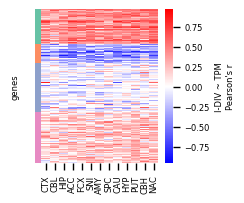

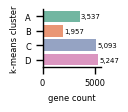

In [ ]:

# n_clusters = 4
# cluster_df, row_colors = make_kmeans(SMTSD_pearson_dict['coeff'], k=n_clusters)
# fig, ax = plt.subplots(1, 1, figsize=(len(SMTSD_pearson_dict['coeff'].columns) / 6.9, 2))
# sorted_cols = cluster_df.drop(columns=['km']).median().sort_values().index
# sns.heatmap(cluster_df.drop(columns='km')[sorted_cols].rename(columns={c: brain_regions_abb['Brain - ' + c] for c in cluster_df.drop(columns='km').columns if c in 'Brain - ' + c}), 
#             cmap='bwr', center=0, yticklabels=False, cbar_kws={'label': "I-DIV ~ TPM Pearson's r"}, ax = ax) # RdYlBu_r
# ax.tick_params(axis='y', which='major', pad=20*2, length=0) # extra padding to leave room for the row colors
# for i, color in enumerate(row_colors):
#         ax.add_patch(plt.Rectangle(xy=(-0.05, i), width=0.05, height=1, color=color, lw=0,
#                                 transform=ax.get_yaxis_transform(), clip_on=False))
# ax.set_ylabel('genes', labelpad=16)
# cluster_palette = row_colors.to_frame(name='color').join(cluster_df['km']).drop_duplicates('km').set_index('km')['color'].to_dict()
# ax.tick_params(left=False, bottom=False)
# ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/heatmap.png', format='png', dpi=300, bbox_inches='tight')

# fig, ax = plt.subplots(figsize=(0.75, 0.75))
# sns.barplot(data = cluster_df.km.value_counts().sort_index().to_frame().reset_index().rename(columns={'count': 'gene count', 'km': 'kmeans cluster'}), 
#             y = 'kmeans cluster', x = 'gene count', hue = 'kmeans cluster', palette=cluster_palette, orient='h',
#             dodge=False, ax=ax)
# ax.tick_params(length=2.5) 
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# ax.set_ylabel('k-means cluster')
# sns.despine()

# for i,v in cluster_df.km.value_counts().sort_index().to_dict().items():
#     plt.text(y=ord(i) - 65, x = v + 100, s=f'{v:,}', va='center', fontsize=5)
    
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/barplot.png', format='png', dpi=300, bbox_inches='tight')

# cluster_df = cluster_df.join(gene_info.gene_name).join(pd.Series(row_colors, name = 'color'))
# cluster_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.csv.gz', compression='gzip', index=True)
# enrichr_df = pd.concat([do_enrichr(glist = cluster_df.loc[cluster_df['km'] == k, 'gene_name'].to_list(), background_genelist =cluster_df.loc[:, 'gene_name'].to_list() ,gr=k )   for k in cluster_df.km.unique()])
# enrichr_df.to_csv(pth + f'tables_intro/{cluster_df.km.nunique()}kmeans_SMTSD_brain.{len(cluster_df)}genes.enrichr.csv.gz', compression='gzip', index=False)

# s=f''' 
#       KM cluster of Pearsons coefficients. 
#       Pearsons correlations were calculated on every gene across samples with DIV>0. Tests that the number of samples were smaller than 0 were assigned as insignificant. Insignificant correlations were set to coefficient of 0 and p-value of 1.
#       coefficients were clustered (ngenes={len(cluster_df)}), using SMTSD tissues from brain ({metadata.loc[metadata.SMTS == 'Brain', 'SMTSD'].nunique()} SMTSD tissues). 
#       (a) Heatmap: Pearson correlation coefficients of isoform diversity with gene expression, sorted by k-means (k={n_clusters}) clustering of Pearsons coefficients.
#       Every gene cluster was tested with overrepresentation analysis using GSEA. Background list contains all genes used for the analysis {len(cluster_df)} and query lists were every of the 4 clusters apart: 
#       A (n={len(cluster_df[cluster_df.km=='A'])}), B (n={len(cluster_df[cluster_df.km=='B'])}), C (n={len(cluster_df[cluster_df.km=='C'])}), D (n={len(cluster_df[cluster_df.km=='D'])})
#       box plots: show the mean isoform diversity, mean gene expression, mean number of isoforms expressed, number of exons and gene length for each gene cluster.       
#       '''

# with open(pth + f'figs_intro/km_SMTSD_brain/about.txt', 'w') as f:
#     f.write(s)
#     f.close()
# nnow()

### examples of clusters

In [ ]:
# k = 'B'
# cluster_df[cluster_df.km == k].drop(columns = ['km', 'color', 'gene_name']).idxmin().to_dict()

{'Cortex': 'ENSG00000115616',
 'Cerebellum': 'ENSG00000152049',
 'Hippocampus': 'ENSG00000277639',
 'Anterior cingulate cortex (BA24)': 'ENSG00000184557',
 'Caudate (basal ganglia)': 'ENSG00000186714',
 'Nucleus accumbens (basal ganglia)': 'ENSG00000275410',
 'Putamen (basal ganglia)': 'ENSG00000104059',
 'Frontal Cortex (BA9)': 'ENSG00000165105',
 'Cerebellar Hemisphere': 'ENSG00000184557',
 'Hypothalamus': 'ENSG00000277639',
 'Substantia nigra': 'ENSG00000172724',
 'Spinal cord (cervical c-1)': 'ENSG00000174567',
 'Amygdala': 'ENSG00000268182'}

 gene PPP1R11
Example of gene found at SMTS Anterior cingulate cortex (BA24)
from cluster: A
(b) Scatterplot: Every datapoint is a sample (n=85). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (4), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=4
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=4
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.55
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.18
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isofo

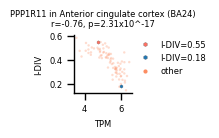

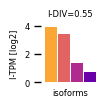

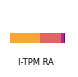

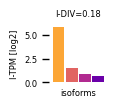

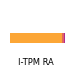

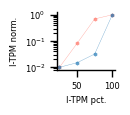

In [ ]:
# gid = 'ENSG00000204619' ; gn = gene_info.loc[gid, 'gene_name']
# t = 'Anterior cingulate cortex (BA24)' ; nnis = 4 # 3 4 5
# k = cluster_df.loc['ENSG00000240184', 'km']
# iinfo = f'{n_clusters}kmeans_SMTSD_brain'
# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.index]

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}


# fig, ax = plt.subplots(figsize=(0.75,0.75))
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other')
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTSD_brain')

# isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')


# s=f''' gene {gn}
# Example of gene found at SMTS {t}
# from cluster: {k}
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''

# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()

In [ ]:
# k = 'A'
# cluster_df[cluster_df.km == k].drop(columns = ['km', 'color', 'gene_name']).idxmin().to_dict()

{'Cortex': 'ENSG00000019144',
 'Cerebellum': 'ENSG00000185963',
 'Hippocampus': 'ENSG00000161609',
 'Anterior cingulate cortex (BA24)': 'ENSG00000180264',
 'Caudate (basal ganglia)': 'ENSG00000108100',
 'Nucleus accumbens (basal ganglia)': 'ENSG00000140798',
 'Putamen (basal ganglia)': 'ENSG00000186487',
 'Frontal Cortex (BA9)': 'ENSG00000100413',
 'Cerebellar Hemisphere': 'ENSG00000185518',
 'Hypothalamus': 'ENSG00000196218',
 'Substantia nigra': 'ENSG00000134779',
 'Spinal cord (cervical c-1)': 'ENSG00000110013',
 'Amygdala': 'ENSG00000221955'}

 gene PCDHGC3
Example of gene found at SMTS Cerebellar Hemisphere
from cluster: A
(b) Scatterplot: Every datapoint is a sample (n=139). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (6), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=6
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=6
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.46
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.17
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange

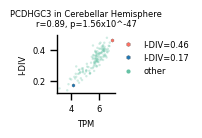

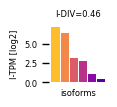

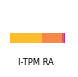

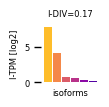

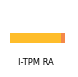

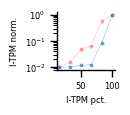

In [ ]:
# gid = 'ENSG00000240184'
# k = cluster_df.loc['ENSG00000240184', 'km']
# t = 'Cerebellar Hemisphere' ; nnis = 6 # 4 5 6 7
# iinfo = f'{n_clusters}kmeans_SMTSD_brain'
# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.index]

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}

# gn = gene_info.loc[gid, 'gene_name']
# fig, ax = plt.subplots(figsize=(0.75,0.75))
# # sns.scatterplot(data = gene_metrics[(gene_metrics.SMTS == t) ], x = 'TPM', y = 'I-DIV', 
# #                 edgecolor= 'None', c= 'silver', s=3, alpha = 1)
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other')
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + '.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTSD_brain')

# isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')

# s=f''' gene {gn}
# Example of gene found at SMTS {t}
# from cluster: {k}
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''

# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()

### clustr general metrics

In [ ]:
# cluster_df = pd.read_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.csv.gz', compression='gzip', index_col=0)
# enrichr_df = pd.read_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.enrichr.csv.gz', compression='gzip')


    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = 267.33, df between = 3, df within = 15830, p=2.89e-169  
    


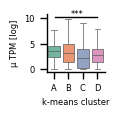

In [ ]:
# colname = 'TPM [log] mean'
# SMTSD_brain_cols = [' - '.join(['Brain', c]) for c in cluster_df.drop(columns=['km', 'gene_name', 'color']).columns]
# boxplot_df = tpm[ list(metadata.loc[metadata.SMTSD.isin(SMTSD_brain_cols)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
# boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.mtpm.csv.gz')
# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=boxplot_df, x='km', y=colname, palette=cluster_palette, 
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
#             fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
# # ax.set_xticks([])
# ax.set(xlabel='k-means cluster', ylabel = 'µ TPM')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# f, p, df_between, df_within = do_anova(group_lists_dict = {k: boxplot_df.loc[boxplot_df.km == k, colname] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''

# ax.axhline(y = 10.25, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=10.25, x = 1.15, s = p_value_to_asterisks(p))
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.mtpm.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.mtpm.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of DIV on clustered groups. 
    F = 1268.01, df between = 3, df within = 15830, p<10^-323  
    


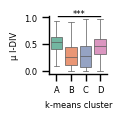

In [ ]:
# colname = 'DIV mean'
# SMTSD_brain_cols = [' - '.join(['Brain', c]) for c in cluster_df.drop(columns=['km', 'gene_name', 'color']).columns]
# boxplot_df = div[ list(metadata.loc[metadata.SMTSD.isin(SMTSD_brain_cols)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
# boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.midiv.csv.gz', compression='gzip', index=True)

# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=boxplot_df, x='km', y=colname, palette=cluster_palette, 
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
#             fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)

# ax.set(xlabel='k-means cluster', ylabel = 'µ I-DIV')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()


# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: boxplot_df.loc[boxplot_df.km == k, colname] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)
# ax.axhline(y = 1.02, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=1.02, x = 1.15, s = p_value_to_asterisks(p))
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTS_brain.{ngenes}genes.div.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTS.{ngenes}genes.div.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of NIS on clustered groups. 
    F = 1021.00, df between = 3, df within = 15830, p<10^-323  
    


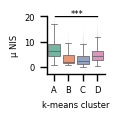

In [ ]:
# colname = 'NIS mean'
# SMTSD_brain_cols = [' - '.join(['Brain', c]) for c in cluster_df.drop(columns=['km', 'gene_name', 'color']).columns]
# boxplot_df = nis[ list(metadata.loc[metadata.SMTSD.isin(SMTSD_brain_cols)].index)].mean(axis = 'columns').to_frame(name=colname).join(cluster_df.km)
# boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.mnis.csv.gz', compression='gzip', index=True)
# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=boxplot_df, x='km', y=colname, palette=cluster_palette, 
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
#             fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)

# ax.set(xlabel='k-means cluster', ylabel = 'µ NIS')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# ax.set_ylim(ax.set_ylim()[0], 20.1)

# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: boxplot_df.loc[boxplot_df.km == k, colname] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)
# ax.axhline(y = 20.05, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=20.05, x = 1.15, s = p_value_to_asterisks(p))
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.mnis.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.mnis.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of number of exons on clustered groups. 
    F = 935.05, df between = 3, df within = 15830, p<10^-323  
    


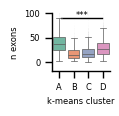

In [ ]:
# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# colname = 'nexons'
# boxplot_df = gene_info.join(cluster_df.km)
# boxplot_df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.nexons_and_glength.csv.gz', compression='gzip', index=True)

# sns.boxplot(data=boxplot_df.dropna(subset=['km']), 
#             x='km', y=colname, palette=cluster_palette, 
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1},
#             fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)
# ax.set(xlabel='k-means cluster', ylabel='n exons')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# ax.set_ylim(ax.set_ylim()[0], 100)

# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: gene_info.join(cluster_df.km).loc[gene_info.join(cluster_df.km).km == k, colname] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)

# ax.axhline(y = 90, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=90, x = 1.15, s = p_value_to_asterisks(p))

# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{colname}.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{colname}.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of gene length on clustered groups. 
    F = 16.48, df between = 3, df within = 15830, p=1.08e-10  
    


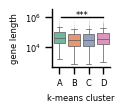

In [ ]:
# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# colname = 'length'
# sns.boxplot(data=gene_info.join(cluster_df.km).dropna(subset=['km']), 
#             x='km', y=colname, palette=cluster_palette, 
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1},
#             fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)

# ax.set(xlabel='k-means cluster', ylabel='gene length')
# sns.despine()
# ax.set_yscale('log')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: gene_info.join(cluster_df.km).loc[gene_info.join(cluster_df.km).km == k, colname] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)


# ax.axhline(y = 10**6, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=10**6, x = 1.15, s = p_value_to_asterisks(p))

# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.glength.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.g{colname}.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of potential number of isoforms on clustered groups. 
    F = 908.23, df between = 3, df within = 15830, p<10^-323  
    


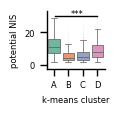

In [ ]:
# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# colname = 'npt_isoforms'
# sns.boxplot(data=gene_info.join(cluster_df.km).dropna(subset=['km']), 
#             x='km', y=colname, palette=cluster_palette, 
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1},
#             fliersize=0.75, linewidth=0.5, order=sorted(cluster_df.km.unique()), zorder = 5, ax=ax)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)
# # ax.set_xticks([])
# ax.set(xlabel='k-means cluster', ylabel='potential NIS')
# sns.despine()
# ax.set_ylim(ax.set_ylim()[0], 33)
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: gene_info.join(cluster_df.km).loc[gene_info.join(cluster_df.km).km == k, colname] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)

# ax.axhline(y = 30, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=30, x = 1.15, s = p_value_to_asterisks(p))

# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{colname}.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{colname}.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of Pearson correlation DIV ~ NIS coefficients on clustered groups. 
    F = 1551.82, df between = 3, df within = 15830, p<10^-323  
    


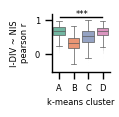

In [ ]:
# # df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/div_nis/all.pearson.csv')
# df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTSD_brain_regions/div_nis.pearson.csv')
# df = df[df.coeff != 'coeff']
# df.coeff = df.coeff.astype(float)
# df.pval = df.pval.astype(float)
# df.drop_duplicates(subset=['Unnamed: 0'], inplace=True)
# df.set_index('Unnamed: 0', inplace=True)
# df = df.join(cluster_df.km.to_frame())

# df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.r_DIV_NIS.csv.gz', compression='gzip', index=True)


# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=df, x='km', y='coeff', palette=cluster_palette,
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
#             fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
# ax.set(ylabel='I-DIV ~ NIS\npearson r', xlabel='k-means cluster')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()


# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'coeff'] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)

# ax.axhline(y = 1.1, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=1.1, x = 1.15, s = p_value_to_asterisks(p))


# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.r_DIV_NIS.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTS.{ngenes}genes.{colname}.r_DIV_NIS.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of Pearson correlation TPM ~ NIS coefficients on clustered groups. 
    F = 1191.77, df between = 3, df within = 15830, p<10^-323  
    


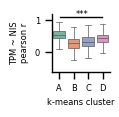

In [ ]:
# df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTSD_brain_regions/nis_tpm.pearson.csv')
# df = df[df.coeff != 'coeff']
# df.coeff = df.coeff.astype(float)
# df.pval = df.pval.astype(float)
# df.drop_duplicates(subset=['Unnamed: 0'], inplace=True)
# df.set_index('Unnamed: 0', inplace=True)
# # df = df.assign(mean_nis = nis.mean(axis='columns'))
# df = df.join(cluster_df.km.to_frame())
# df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.r_TPM_NIS.csv.gz', compression='gzip', index=True)


# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=df, x='km', y='coeff', palette=cluster_palette,
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
#             fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
# ax.set(ylabel='TPM ~ NIS\npearson r', xlabel='k-means cluster')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'coeff'] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)
# ax.axhline(y = 1.1, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=1.1, x = 1.15, s = p_value_to_asterisks(p))


# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.r_TPM_NIS.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.r_TPM_NIS.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of Pearson correlation DIV ~ TPM coefficients on clustered groups. 
    F = 8873.21, df between = 3, df within = 15830, p<10^-323  
    


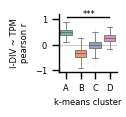

In [ ]:
# df = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_div_tpm/SMTSD_brain_regions/div_tpm.pearson.csv')
# df = df[df.coeff != 'coeff']
# df.coeff = df.coeff.astype(float)
# df.pval = df.pval.astype(float)
# df.drop_duplicates(subset=['Unnamed: 0'], inplace=True)
# df.set_index('Unnamed: 0', inplace=True)
# df = df.join(cluster_df.km.to_frame())
# df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.r_DIV_TPM.csv.gz', compression='gzip', index=True)

# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=df, x='km', y='coeff', palette=cluster_palette,
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
#             fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
# ax.set(ylabel='I-DIV ~ TPM\npearson r', xlabel='k-means cluster')
# ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'coeff'] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)

# ax.axhline(y = 1.1, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=1.1, x = 1.15, s = p_value_to_asterisks(p))


# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.r_DIV_TPM.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.r_DIV_TPM.about.txt', 'w') as file:
#     file.write(s)
#     file.close()


    one-way ANOVA test for the effect of Pearson correlation DIV ~ TPM coefficients on clustered groups. 
    F = 348.93, df between = 3, df within = 15830, p=1.95e-219  
    


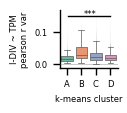

In [ ]:
# df = cluster_df.drop(columns=['km', 'gene_name', 'color']).var(axis='columns').to_frame(name='var').join(cluster_df.km)
# df.to_csv(pth + f'tables_intro/{n_clusters}kmeans_SMTSDbrain.{ngenes}genes.var_coeff.csv.gz', compression='gzip', index=True)

# fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
# sns.boxplot(data=df, x='km', y='var', palette=cluster_palette,
#             flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':1, 'markersize': 0.1}, order = ['A', 'B', 'C', 'D'],
#             fliersize=0.75, linewidth=0.5, zorder = 2)#.grid(axis = 'y', color = 'silver', zorder = 1, linestyle = '--', alpha = 0.5)    
# ax.set(ylabel='I-DIV ~ TPM\npearson r var', xlabel='k-means cluster')
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# f, p, df_between, df_within = f, p, df_between, df_within = do_anova(group_lists_dict = {k: df.loc[df.km == k, 'var'] for k in cluster_df.km.unique()})
# s = f'''
#     one-way ANOVA test for the effect of what is described in the file name. 
#     F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
#     '''
# print(s)

# ax.axhline(y = 0.15, xmin=0.15,xmax=0.87,color='k',linewidth = 1)
# ax.text(y=0.15, x = 1.15, s = p_value_to_asterisks(p))
# ax.axhline(y=0, color='dimgrey', linestyle='-', alpha=0.5, linewidth=0.5, zorder=3)
# ax.set_ylim(ax.get_ylim()[0], 0.17)

# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.var_coeff.png', format='png', dpi=300, bbox_inches='tight')
# with open(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.var_coeff.about.txt', 'w') as file:
#     file.write(s)
#     file.close()

### enrichment analysis

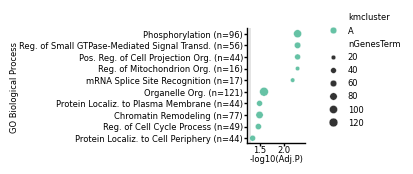

In [ ]:
# gs = 'GO_Biological_Process_2025'
# label_abbrev = {
#     "Phosphorylation (n=96)": "Phosphorylation (n=96)",
#     "Regulation of Small GTPase Mediated Signal Transduction (n=56)": "Reg. of Small GTPase-Mediated Signal Transd. (n=56)",
#     "Positive Regulation of Cell Projection Organization (n=44)": "Pos. Reg. of Cell Projection Org. (n=44)",
#     "Regulation of Mitochondrion Organization (n=16)": "Reg. of Mitochondrion Org. (n=16)",
#     "mRNA Splice Site Recognition (n=17)": "mRNA Splice Site Recognition (n=17)",
#     "Organelle Organization (n=121)": "Organelle Org. (n=121)",
#     "Protein Localization to Plasma Membrane (n=44)": "Protein Localiz. to Plasma Membrane (n=44)",
#     "Chromatin Remodeling (n=77)": "Chromatin Remodeling (n=77)",
#     "Regulation of Cell Cycle Process (n=49)": "Reg. of Cell Cycle Process (n=49)",
#     "Protein Localization to Cell Periphery (n=44)": "Protein Localiz. to Cell Periphery (n=44)",
# }

# enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
# fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/6.7))
# sns.scatterplot(data = enrichr_tmp_df, 
#             x = '-log10(Adjusted P-value)', y = 'Term', hue = 'kmcluster', palette=cluster_palette, 
#             size='nGenesTerm', sizes=(10,40), zorder = 5, ax=ax)
# labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
# labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
# ax.set_yticklabels(labels)
# # ax.legend().remove()
# ax.legend(bbox_to_anchor = (1.2,1.2), frameon=False)
# ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)

# ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
# ax.set_xlim(ax.get_xlim()[0]* 0.95, ax.get_xlim()[1] * 1.05)
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels([label_abbrev[t.get_text()] for t in ax.get_yticklabels()],x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{gs}.png', format='png', dpi=300, bbox_inches='tight')


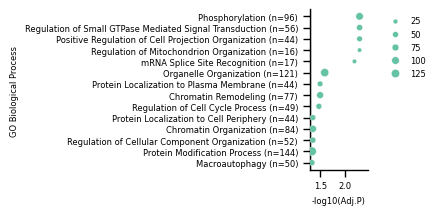

In [ ]:
# kmcluster_ = 'A'    
# enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)
# fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/6.7))
# sns.scatterplot(data = enrichr_tmp_df, 
#             x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
#             size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5)
# ax.legend(bbox_to_anchor = (1.2,1), frameon=False)
# labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
# labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
# ax.set_yticklabels(labels)
# ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
# ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
# ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
# sns.despine()
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{gs}.cluster{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


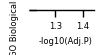

In [ ]:
# kmcluster_ = 'B'

    
# enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)
# fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/5))
# sns.scatterplot(data = enrichr_tmp_df, 
#             x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
#             size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5)
# ax.legend().remove()
# labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
# labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
# ax.set_yticklabels(labels)
# ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
# ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
# ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
# sns.despine()
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{gs}.cluster{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


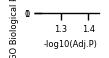

In [ ]:
# kmcluster_ = 'C'    
# enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)
# fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/5))
# sns.scatterplot(data = enrichr_tmp_df, 
#             x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
#             size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5)
# ax.legend().remove()
# labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
# labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
# ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
# ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
# ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
# sns.despine()
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{gs}.cluster{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


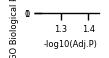

In [ ]:
# kmcluster_ = 'D'


# enrichr_tmp_df = enrichr_df[(enrichr_df.Gene_set == gs) & (enrichr_df['Adjusted P-value'] < 0.05) & (enrichr_df.kmcluster == kmcluster_)].sort_values('Adjusted P-value').head(15)
# fig, ax = plt.subplots(figsize=(0.75,len(enrichr_tmp_df)/5))
# sns.scatterplot(data = enrichr_tmp_df, 
#             x = '-log10(Adjusted P-value)', y = 'Term', color = cluster_palette[kmcluster_], 
#             size='nGenesTerm', sizes=(10,40), ax=ax, zorder = 5).grid(axis = 'y', color = 'silver', zorder = 0, linestyle = '--', alpha = 0.5)
# ax.legend().remove()
# labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
# labels = [label + f' (n={list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(enrichr_tmp_df.loc[enrichr_tmp_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
# ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
# ax.set(ylabel = gs.replace('_', ' ').replace('2025', ''), xlabel = '-log10(Adj.P)')
# ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] * 1.05)
# sns.despine()
# fig.savefig(pth + f'figs_intro/km_SMTSD_brain/{n_clusters}kmeans_SMTSD_brain.{ngenes}genes.{gs}.cluster{kmcluster_}.png', format='png', dpi=300, bbox_inches='tight')

### examples of genes from specific GO terms

In [ ]:
# k = 'A'
# gs = 'GO_Biological_Process_2025'
# tm = 'Phosphorylation (GO:0016310)'
# gns = enrichr_df.loc[(enrichr_df.Gene_set == gs) & (enrichr_df.Term == tm) & (enrichr_df.kmcluster == k), 'Genes'].values[0].split(';') # gene names
# minvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns=['km', 'color', 'gene_name']).idxmax().to_dict()
# minvals

{'Cortex': 'ENSG00000110931',
 'Cerebellum': 'ENSG00000171603',
 'Hippocampus': 'ENSG00000164924',
 'Anterior cingulate cortex (BA24)': 'ENSG00000110931',
 'Caudate (basal ganglia)': 'ENSG00000198586',
 'Nucleus accumbens (basal ganglia)': 'ENSG00000160145',
 'Putamen (basal ganglia)': 'ENSG00000007264',
 'Frontal Cortex (BA9)': 'ENSG00000110931',
 'Cerebellar Hemisphere': 'ENSG00000100030',
 'Hypothalamus': 'ENSG00000164924',
 'Substantia nigra': 'ENSG00000110680',
 'Spinal cord (cervical c-1)': 'ENSG00000072518',
 'Amygdala': 'ENSG00000105397'}


Example of gene found at 
gene set: GO Biological Process 2025
enriched term: Phosphorylation (GO:0016310) – CAMKK2 gene.
(b) Scatterplot: Every datapoint is a sample (n=85). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (9), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=9
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=9
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.54
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.26
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons repre

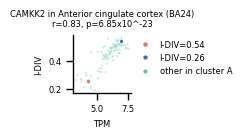

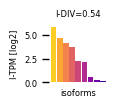

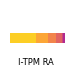

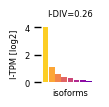

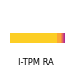

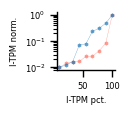

In [ ]:
# t = 'Anterior cingulate cortex (BA24)'
# gid = minvals[t] ; gn = gene_info.loc[gid, 'gene_name']
# nnis = 9
# iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])

# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.index]
# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_min,nnis_max])}

# fig, ax = plt.subplots(figsize=(0.75,0.75))
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)

# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster ' + k)
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info='maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info='minDIV', o='km_SMTSD_brain')

# isoform_expression_lineplot(spl_min=nnis_max, spl_max=nnis_min, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')

# s=f'''
# Example of gene found at 
# gene set: {gs.replace('_', ' ')}
# enriched term: {tm} – {gn} gene.
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''

# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()


Example of gene found at 
gene set: GO Biological Process 2025
enriched term: Phosphorylation (GO:0016310) – PINK1 gene.
(b) Scatterplot: Every datapoint is a sample (n=129). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (3), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=3
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=3
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.69
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.12
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons repre

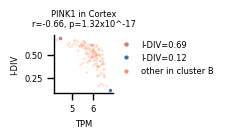

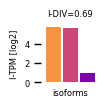

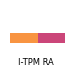

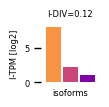

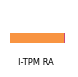

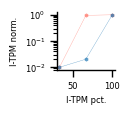

In [ ]:
# gid = 'ENSG00000158828' ; gn = gene_info.loc[gid, 'gene_name']
# t = 'Cortex' ; nnis = 3
# iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])

# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.loc[gene_metrics.SMTSD.str.contains(t)].index]
# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)
# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}

# fig, ax = plt.subplots(figsize=(0.75,0.75))
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)

# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster ' + cluster_df.loc[gid, 'km'])
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info='maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info='minDIV', o='km_SMTSD_brain')

# isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')

# s=f'''
# Example of gene found at 
# gene set: {gs.replace('_', ' ')}
# enriched term: {tm} – {gn} gene.
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''
# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()
# nnow()


Example of gene found at 
gene set: GO Biological Process 2025
enriched term: Phosphorylation (GO:0016310) – APP gene.
(b) Scatterplot: Every datapoint is a sample (n=107). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (11), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=11
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=11
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.52
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.28
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons repr

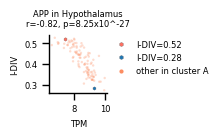

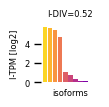

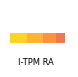

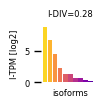

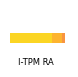

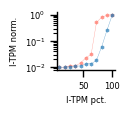

In [ ]:
# gid = gene_info[gene_info.gene_name == 'APP'].index[0]
# gn = gene_info.loc[gid, 'gene_name']
# t = 'Hypothalamus' ; nnis = 11 # 11 12 13 14 15
# iinfo = f'GO_Cellular_Component_2025.B.Mitochondrial_Membrane_GO_0031966'

# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.loc[gene_metrics.SMTSD.str.contains(t)].index]
# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)
# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_max,nnis_min])}


# fig, ax = plt.subplots(figsize=(0.75,0.75))
# # sns.scatterplot(data = gene_metrics[(gene_metrics.SMTS == t) ], x = 'TPM', y = 'I-DIV', 
# #                 edgecolor= 'None', c= 'silver', s=3, alpha = 1)
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster ' + k)
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()
# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTSD_brain')

# isoform_expression_lineplot(spl_min=nnis_min, spl_max=nnis_max, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')
# s=f'''
# Example of gene found at 
# gene set: {gs.replace('_', ' ')}
# enriched term: {tm} – {gn} gene.
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''

# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()

In [ ]:
# k = 'A'
# gs = 'GO_Biological_Process_2025'
# tm = 'mRNA Splice Site Recognition (GO:0006376)'
# gns = enrichr_df.loc[(enrichr_df.Gene_set == gs) & (enrichr_df.Term == tm) & (enrichr_df.kmcluster == k), 'Genes'].values[0].split(';') # gene names
# minvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns=['km', 'color', 'gene_name']).idxmax().to_dict()
# minvals

{'Cortex': 'ENSG00000101489',
 'Cerebellum': 'ENSG00000107290',
 'Hippocampus': 'ENSG00000146963',
 'Anterior cingulate cortex (BA24)': 'ENSG00000161082',
 'Caudate (basal ganglia)': 'ENSG00000161082',
 'Nucleus accumbens (basal ganglia)': 'ENSG00000146963',
 'Putamen (basal ganglia)': 'ENSG00000101489',
 'Frontal Cortex (BA9)': 'ENSG00000161082',
 'Cerebellar Hemisphere': 'ENSG00000099995',
 'Hypothalamus': 'ENSG00000146963',
 'Substantia nigra': 'ENSG00000099995',
 'Spinal cord (cervical c-1)': 'ENSG00000099995',
 'Amygdala': 'ENSG00000140488'}

number of samples in the scatterplot: 129

Example of gene found at 
gene set: GO Biological Process 2025
enriched term: mRNA Splice Site Recognition (GO:0006376) – CELF4 gene.
(b) Scatterplot: Every datapoint is a sample (n=129). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (14), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=14
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=14
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.71
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.43
(e) lineplot: sho

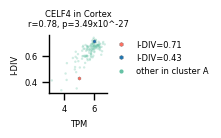

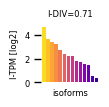

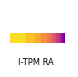

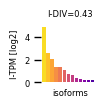

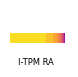

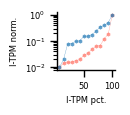

In [ ]:
# gid = minvals['Cortex'] 
# gn = gene_info.loc[gid, 'gene_name']
# t = 'Cortex' ; nnis = 14
# iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])
# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.index]

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_min,nnis_max])}

# fig, ax = plt.subplots(figsize=(0.75,0.75))
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster ' + k)
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + f'.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gn, n_nis=nnis, savefig=True, info=f'minDIV', o='km_SMTSD_brain')
# isoform_expression_lineplot(spl_min=nnis_max, spl_max=nnis_min, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')
# print(f'number of samples in the scatterplot: {len(gene_metrics)}')


# s=f'''
# Example of gene found at 
# gene set: {gs.replace('_', ' ')}
# enriched term: {tm} – {gn} gene.
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''
# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()


In [ ]:
# k = 'A'
# gs = 'GO_Cellular_Component_2025'
# tm = 'Neuron Projection (GO:0043005)'
# gns = enrichr_df.loc[(enrichr_df.Gene_set == gs) & (enrichr_df.Term == tm) & (enrichr_df.kmcluster == k), 'Genes'].values[0].split(';') # gene names
# minvals = cluster_df.loc[cluster_df.gene_name.isin(gns)].drop(columns=['km', 'color', 'gene_name']).idxmax().to_dict()
# minvals

{'Cortex': 'ENSG00000055163',
 'Cerebellum': 'ENSG00000103549',
 'Hippocampus': 'ENSG00000149043',
 'Anterior cingulate cortex (BA24)': 'ENSG00000100505',
 'Caudate (basal ganglia)': 'ENSG00000106123',
 'Nucleus accumbens (basal ganglia)': 'ENSG00000145362',
 'Putamen (basal ganglia)': 'ENSG00000106123',
 'Frontal Cortex (BA9)': 'ENSG00000140945',
 'Cerebellar Hemisphere': 'ENSG00000055163',
 'Hypothalamus': 'ENSG00000114030',
 'Substantia nigra': 'ENSG00000114030',
 'Spinal cord (cervical c-1)': 'ENSG00000072518',
 'Amygdala': 'ENSG00000130638'}


Example of gene found at 
gene set: GO Cellular Component 2025
enriched term: Neuron Projection (GO:0043005) – CDH13 gene.
(b) Scatterplot: Every datapoint is a sample (n=110). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms (5), relatively in similar gene expression level, and different isoform diversity. 
bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n=5
stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n=5
The colors between the bar and the stacked are matched to the same isoforms.
(c) Bar plot + stacked bar plot represent the isoform diversity = 0.54
(d) Bar plot + stacked bar plot represent the isoform diversity = 0.25
(e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons rep

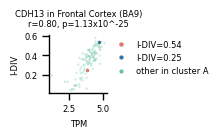

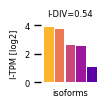

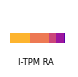

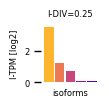

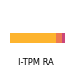

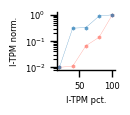

In [ ]:

# t = 'Frontal Cortex (BA9)'
# gid = minvals[t] ; gn = gene_info.loc[gid, 'gene_name']
# nnis = 5 # 4 5
# iinfo = '.'.join([f'km{k}', gs, tm.replace(' ', '_').replace(':', '') ])
# gene_metrics = get_gene_metrics(gene=gid)
# gene_metrics = gene_metrics.loc[gene_metrics.SMTSD == 'Brain - ' + t]
# isoforms_df = get_isoforms_from_gene(gene=gid)
# isoforms_df = isoforms_df[gene_metrics.index]

# nnis_max = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmax()
# nnis_min = gene_metrics.loc[gene_metrics.NIS == nnis, 'I-DIV'].idxmin()

# isoforms_df.to_csv(pth + 'tables_intro/' + f'isoforms_df.{gn}.csv.gz', compression='gzip', index=True)
# gene_metrics.to_csv(pth + 'tables_intro/' + f'gene_metrics.{gn}.csv.gz', compression='gzip', index=True)

# c_palette = {c: s_colors[i] for i, c in enumerate([nnis_min, nnis_max])}


# fig, ax = plt.subplots(figsize=(0.75,0.75))
# # sns.scatterplot(data = gene_metrics[(gene_metrics.SMTS == t) ], x = 'TPM', y = 'DIV', 
# #                 edgecolor= 'None', c= 'silver', s=3, alpha = 1)
# sns.scatterplot(data = gene_metrics, x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'None', c= cluster_df.loc[gid, 'color'], s=3, alpha = 0.3)

# for c in [nnis_max,nnis_min]:
#     sns.scatterplot(data = gene_metrics.loc[[c]], x = 'TPM', y = 'I-DIV', 
#                 edgecolor= 'dimgrey', c= c_palette[c], s=6, marker='h',alpha = 1)
# legend_handles = [
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[0],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_max]:.2f}'),
#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=s_colors[1],markeredgewidth=0.25,
#            markeredgecolor='dimgrey', markersize=3, label=f'I-DIV={div.loc[gid, nnis_min]:.2f}'),
#     Line2D([], [], marker='o', linestyle='None', markerfacecolor=cluster_df.loc[gid, 'color'],
#            markeredgecolor='none', markersize=3, label='other in cluster ' + k)
# ]
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1))
# ax.set_title(' in '.join([gn,t]) + '\n' + ', '.join([f'r={SMTSD_pearson_dict['coeff'].loc[gid, t]:.2f}' ,'p=' + format_small_number(SMTSD_pearson_dict['pval'].loc[gid, t])]))
# ax.tick_params(length=2.5) ## other options are right and top
# ax.set_yticklabels(ax.get_yticklabels(),x=0.07)
# ax.set_xticklabels(ax.get_xticklabels(), ha='center',y=0.05)
# ax.set_xlabel(ax.get_xlabel(),labelpad=0)
# ax.set_ylabel(ax.get_ylabel(),labelpad=0)
# sns.despine()

# fig.savefig(pth + 'figs_intro/km_SMTSD_brain/' + gn + f'.{iinfo}.DIV_TPM.{nnis}_NIS.n_{len(gene_metrics)}.png', format='png', dpi=300, bbox_inches='tight')

# isoform_expression_barplots(smpl=nnis_max, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info='maxDIV', o='km_SMTSD_brain')
# isoform_expression_barplots(smpl=nnis_min, 
#                             isoforms_df=isoforms_df, gn=gene_info.loc[gid, 'gene_name'], n_nis=nnis, savefig=True, info='minDIV', o='km_SMTSD_brain')
# isoform_expression_lineplot(spl_min=nnis_max, spl_max=nnis_min, gn=gn, n_nis=nnis, savefig=True, o='km_SMTSD_brain')

# s=f'''
# Example of gene found at 
# gene set: {gs.replace('_', ' ')}
# enriched term: {tm} – {gn} gene.
# (b) Scatterplot: Every datapoint is a sample (n={len(gene_metrics)}). Scatterplot and Pearson’s correlation test of isoform diversity and gene expression log2(TPM+1). 
# Orange and blue hexagon datapoints represent examples of two samples of the gene that share the same number of isoforms ({nnis}), relatively in similar gene expression level, and different isoform diversity. 
# bar plot: every bar shows expression of a different isoform in log2(TPM+1), color represented by isoforms. n={nnis}
# stacked bar plot: every color represented by isoform and size shows relative abondance to other isoforms on TPM. n={nnis}
# The colors between the bar and the stacked are matched to the same isoforms.
# (c) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_max, 'I-DIV']:.2f}
# (d) Bar plot + stacked bar plot represent the isoform diversity = {gene_metrics.loc[nnis_min, 'I-DIV']:.2f}
# (e) lineplot: shows isoform expression, shown on scaled TPM. Hexagons represent expression of every isoform. Orange line shows the expression of isoforms in the cerebellum sample ; Blue line shows the expression of isoforms in the liver sample.
# '''
# with open(pth + f'figs_intro/km_SMTSD_brain/{gn}.about.txt', 'w') as f:
#     f.write(s)
#     f.close()
# nnow()